# Calibration and Pricing of Athena Autocalls: Heston Model Using FFT and Monte Carlo
**Underlying:** S&P 500 (SPX)

**Model:** Heston Stochastic Volatility

## 1. Product Term Sheet
**Structure:** Athena Autocall Standard Note (Snowball)
* **Maturity:** 4 Years
* **Observation Frequency:** Semi-Annual; first observation is one year after issuance
* **Coupons:** 3% per period (Snowball feature)
* **Barriers:**
    * **Autocall:** 100% of Initial Strike ($S_t \ge S_{ref}$)
    * **Redemption:** 70% ($S_T \ge 70\%$)
    * **Knock-In:** 60% (Down-and-In Put European style)

**Payoff Logic:**
1.  **Early Exit:** If $S_t \ge 100\%$, redeem principal + accrued coupons.
2.  **Maturity (Safe):** If $S_T \ge 70\%$, redeem principal + final coupon.
3.  **Maturity (Loss):** If $S_T < 60\%$, redeem principal $\times (S_T / S_{ref})$ (principal at risk).

## This run: live snapshot, 30 September 2026
SPX option chain pulled from yfinance at 15:22 EDT on 30 September 2026 (spot 7,696.50), a synchronised intraday snapshot rather than the overnight pull of December 2025. Bloomberg SOFR OIS quotes were not available, so the discount curve is bootstrapped from the FRED Treasury constant-maturity par curve (as of 28 September 2026) and flagged as a proxy; a discount-curve sensitivity is reported with the price. The note is re-struck at today's spot with the same terms (4 years, semi-annual from year 1, 3% snowball, 70% bonus, 60% European knock-in). The same notebook run on the December snapshot is kept as `main_2025-12-03_snapshot.ipynb`.

## What changed in this version (v2, September 2026)
The December 2025 submission is kept in `original_submission/`. This version keeps the same product, data and structure and fixes the points listed under "what would you do differently" in our own review:

1. **Pricing date pinned to the snapshot.** The schedule, the curves and the surface now all refer to 3 December 2025, so the run is reproducible instead of depending on `datetime.now()`.
2. **Quote hygiene.** A static no-arbitrage filter (call-spread slope bound $-e^{-rT} \le \partial C/\partial K \le 0$) removes 23 inconsistent quotes; every one of them last traded 37+ days before the snapshot, including the 4Y 7800 call that alone drove a large share of the old error.
3. **Calibration in vol space, on the expiries the note observes.** Objective = weighted RMSE of implied vols (weights $1/\text{spread}^2$ from the bid-ask in vol terms, floored at half a vol point, one vote per expiry), fitted to 6M-4Y. The 1M and 3M smiles need jumps that Heston does not have and the note has no exposure to them; they are kept as an out-of-sample diagnostic. The DE polish is switched off so the L-BFGS-B step is a real local refinement.
4. **Simulation: Andersen's QE scheme** with martingale correction replaces Euler full truncation (Euler kept as benchmark). The drift is the term structure of forwards from the curves rather than one flat $r-q$, and the observation dates sit exactly on the time grid.
5. **Validation block.** Forward check on the characteristic function, FFT vs direct quadrature, martingale check, MC-vs-FFT vanilla repricing, step-size convergence Euler vs QE, and the Monte Carlo standard error.
6. **Lifecycle details.** 7-day payment lag from the term sheet; the fair coupon is solved with a root-finder on common random numbers.
7. **Bug fixes.** The path plot's payoff added principal on top of the stock payoff when knocked in (it printed 1022); `generate_greek_paths` overwrote the base pricer's paths.


In [1]:
#! pip install yfinance

In [2]:
#! pip install numba

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

from scipy.optimize import brentq
from scipy.stats import norm

import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
from matplotlib.lines import Line2D

import copy


from heston_pricer import (sofr_zero_curve, DF, rate_curve_func, HestonFFTCalibrator, HestonAutocallPricer,
                           suppress_stdout, bs_call_price, implied_vol_call_vec,
                           attach_quote_details, filter_call_spread_arbitrage, set_rate_curve, OISBootstrapper)



In [4]:
# GLOBAL CONSTANTS: FAKE TERM SHEET
DATA_FILE = "calibration_data_September_30_2026.xlsx"   # live SPX snapshot, 30 Sep 2026 15:22 EDT (yfinance)
# DATA_FILE = "calibration_data_December_03_2025.xlsx"  # December 2025 snapshot used for the course submission

# Pricing date = the date of the option snapshot, so the schedule, the curves and the surface
# all refer to the same instant and the notebook gives the same numbers whenever it is run.
_spot_sheet = pd.read_excel(DATA_FILE, sheet_name="Spot Price")
SNAPSHOT_TIME = pd.to_datetime(_spot_sheet['Date'].iloc[0])
PRICING_DATE = SNAPSHOT_TIME.to_pydatetime().replace(hour=0, minute=0, second=0, microsecond=0)
S0 = float(_spot_sheet['S0'].iloc[0])   # Spot price
TODAY = PRICING_DATE

# Discount curve: par quotes saved with the snapshot ('Rates' sheet) when present, else the December 2025 SOFR OIS quotes.
try:
    _rates = pd.read_excel(DATA_FILE, sheet_name="Rates")
    sofr_zero_curve = set_rate_curve(list(zip(_rates['tenor_years'], _rates['rate_pct'])), coupon_freq=2)
    RATE_SOURCE = f"{_rates['source'].iloc[0]}, as of {_rates['as_of'].iloc[-1]}"
except ValueError:
    sofr_zero_curve = set_rate_curve(OISBootstrapper.DEFAULT_MARKET_DATA, coupon_freq=1)
    RATE_SOURCE = "Bloomberg SOFR OIS par swaps, 3 December 2025"

# Generate Schedule
# (Logic: 1st obs at 1yr, then every 6m)
TIME_DELTA = timedelta(days=183)
PRODUCT_SCHEDULE_RAW = [TODAY + 2*TIME_DELTA]

for _ in range(6):
    PRODUCT_SCHEDULE_RAW.append(PRODUCT_SCHEDULE_RAW[-1] + TIME_DELTA)

# Convert to strings for the Pricer
PRODUCT_SCHEDULE = [date.strftime("%Y-%m-%d") for date in PRODUCT_SCHEDULE_RAW]

# Observation times in years from the pricing date (inserted exactly into the simulation grid)
OBS_TIMES = HestonAutocallPricer.schedule_to_times(PRODUCT_SCHEDULE, PRICING_DATE)

# Global Terms Dictionary
PRODUCT_PARAMS = {
    "full_schedule": PRODUCT_SCHEDULE,
    "coupon_step": 0.03,         # 3.00% per period
    "barrier_redemption": 0.70,  # 70%
    "barrier_knock_in": 0.60,    # 60%
    "exit_bonus": 0.03 * 8,      # 8 autocall observation dates
    "nominal": 1000,             # Added nominal for clarity
    "payment_lag_days": 7        # Term sheet: payment 7 calendar days after each valuation date
}

print(f"Snapshot:     {SNAPSHOT_TIME}  (spot {S0:.2f})")
print(f"Pricing date: {TODAY.date()}")
print(f"Discount curve: {RATE_SOURCE}")
print("Zero rates:   " + ", ".join(f"{t}y {100*float(rate_curve_func(t)):.3f}%" for t in [0.25, 1, 2, 4]))
print(f"First obs:    {PRODUCT_SCHEDULE[0]}")
print(f"Final obs:    {PRODUCT_SCHEDULE[-1]}")
print(f"Obs times (y): {np.round(OBS_TIMES, 4)}")
print(PRODUCT_PARAMS)


Snapshot:     2026-09-30 15:22:50.029000  (spot 7696.50)
Pricing date: 2026-09-30
Discount curve: FRED Treasury constant-maturity yield (proxy for SOFR OIS), as of 2026-09-28
Zero rates:   0.25y 4.257%, 1y 4.488%, 2y 4.875%, 4y 4.986%
First obs:    2027-10-01
Final obs:    2030-10-03
Obs times (y): [1.0027 1.5041 2.0055 2.5068 3.0082 3.5096 4.011 ]
{'full_schedule': ['2027-10-01', '2028-04-01', '2028-10-01', '2029-04-02', '2029-10-02', '2030-04-03', '2030-10-03'], 'coupon_step': 0.03, 'barrier_redemption': 0.7, 'barrier_knock_in': 0.6, 'exit_bonus': 0.24, 'nominal': 1000, 'payment_lag_days': 7}


## 2. Market Data & Curve Construction

### Yield Curve
Bootstrapped from the par quotes saved with each snapshot.
* **December 2025 snapshot:** Bloomberg SOFR OIS par swaps; simple rates to 18M, annual par swaps from 2Y.
* **September 2026 snapshot:** FRED Treasury constant-maturity par yields as a proxy for SOFR OIS (Bloomberg not available); simple rates to 1Y, semi-annual par bonds from 2Y. The forward is unaffected by the choice of curve because $q$ is implied from parity with the same curve ($F = K + (C-P)e^{rT}$), but the discounting of the note's cash flows is not: if SOFR OIS sits 20-30 bp below Treasuries at 1-4Y, the note is worth 3-5 per 1,000 more than shown. The sensitivity cell after the price quantifies this.

### Option Data (SPX)
* **Source:** yfinance, synchronised intraday pull (30 September 2026, 15:22 EDT).
* **Filtering:** Liquidity > 1 vol, monotonicity check, arbitrage check ($C > S - Ke^{-rT}$).
* **Quote hygiene (v2):** call-spread bound $-e^{-rT} \le \Delta C/\Delta K \le 0$ between adjacent strikes; of an inconsistent pair we drop the quote that traded less recently. Bid/ask are attached to weight the calibration.
* **Implied Dividend ($q$):** Extracted via Put-Call Parity at the ATM strike of each expiry.


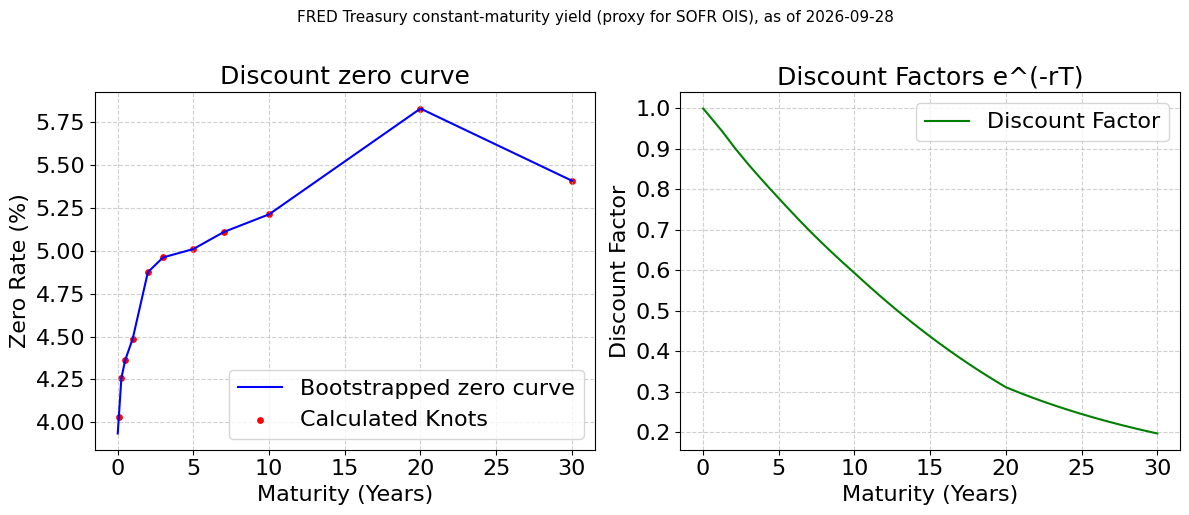

In [5]:
# 1. Generate a time grid from 0 to 30 years
t_grid = np.linspace(0.01, 30, 500)

# 2. Calculate values using your functions
# Note: rate_curve_func returns decimals (0.04), we multiply by 100 for %
zero_rates = rate_curve_func(t_grid) * 100
dfs = DF(t_grid)

# 3. Plotting
plt.figure(figsize=(12, 5))

# Plot 1: Zero Rates
plt.subplot(1, 2, 1)
plt.plot(t_grid, zero_rates, label='Bootstrapped zero curve', color='blue')
plt.suptitle(RATE_SOURCE, fontsize=11, y=1.02)

# Optional: Plot the specific "Known" points calculated by the bootstrapper
# Accessing the internal x/y data of the scipy interpolator
plt.scatter(sofr_zero_curve.x, sofr_zero_curve.y * 100, color='red', s=15, label='Calculated Knots')

plt.title('Discount zero curve', fontsize=18)
plt.xlabel('Maturity (Years)', fontsize=16)
plt.ylabel('Zero Rate (%)', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

# Plot 2: Discount Factors
plt.subplot(1, 2, 2)
plt.plot(t_grid, dfs, label='Discount Factor', color='green')
plt.title('Discount Factors e^(-rT)', fontsize=18)
plt.xlabel('Maturity (Years)', fontsize=16)
plt.ylabel('Discount Factor', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)

plt.tight_layout()
plt.show()

In [6]:
def get_clean_calibration_data(ticker_symbol, min_volume=1):
    """
    Pulls option chain data from yfinance. Doesn't have access to historical data.
    Saves a copy of the data. You need to download it from the sidebar of the Colab notebook.
    You don't need to run this if you already have the data file. Pass the file to resample_semiannual instead.

    Args:
    ticker_symbol: "SPX" for S&P 500
    min_volume: implements minimum volume filtering

    Returns:
    A tuple of the spot price and the clean pandas data frame

    """
    print(f"Retrieving data for {ticker_symbol}")
    asset = yf.Ticker(ticker_symbol)

    # 1. Get spot price
    try:
        history = asset.history(period="1d")
        if history.empty:
            raise ValueError("No historical data found.")
        S0 = history['Close'].iloc[-1]
        print(f"Spot Price (S0): {S0:.2f}")
    except Exception as e:
        print(f"Error getting S0: {e}")
        return None, None

    # 2. Get expirations
    try:
        expirations = asset.options
    except:
        return None, None

    today = datetime.now()
    selected_dates = []

    # Filter dates
    for exp in expirations:
        exp_dt = datetime.strptime(exp, "%Y-%m-%d")
        days = (exp_dt - today).days
        if 30 < days < 1500:
            selected_dates.append(exp)

    all_dfs = []
    raw_dfs = [] # Store raw data for Excel

    for exp in selected_dates:
        exp_date = datetime.strptime(exp, "%Y-%m-%d")
        T = (exp_date - today).days / 365.0
        df_r = DF(T)

        # 1. Retrieve data
        try:
            chain = asset.option_chain(exp)
            calls = chain.calls
            puts = chain.puts
        except:
            continue

        calls['mid_price'] = (calls['bid'] + calls['ask']) / 2
        puts['mid_price'] = (puts['bid'] + puts['ask']) / 2

        # 2. Calculate implied dividend (q)
        try:
            closest_strike_idx = (calls['strike'] - S0).abs().argsort()[:1]
            if closest_strike_idx.empty:
                continue

            K_atm = calls.iloc[closest_strike_idx]['strike'].values[0]

            if K_atm not in puts['strike'].values:
                common_strikes = np.intersect1d(calls['strike'].values, puts['strike'].values)
                if len(common_strikes) == 0:
                    continue
                K_atm = common_strikes[np.abs(common_strikes - S0).argmin()]

            C_atm = calls[calls['strike'] == K_atm]['mid_price'].values[0]
            P_atm = puts[puts['strike'] == K_atm]['mid_price'].values[0]

            parity_val = (C_atm - P_atm + K_atm * df_r) / S0
            if parity_val <= 0:
                implied_q = 0
            else:
                implied_q = -np.log(parity_val) / T

            df_q = np.exp(-implied_q * T)

        except Exception as e:
            print(f"Skipping exp {exp}: Error calc q ({e})")
            continue

        # 3. Select OTM puts & calls
        puts_otm = puts[
            (puts['strike'] < S0) &
            (puts['strike'] > S0 * 0.45) &
            (puts['volume'] >= min_volume)
        ].copy()
        puts_otm['type'] = 'put'

        calls_otm = calls[
            (calls['strike'] >= S0) &
            (calls['strike'] < S0 * 1.25) &
            (calls['volume'] >= min_volume)
        ].copy()
        calls_otm['type'] = 'call'

        df = pd.concat([puts_otm, calls_otm])
        if df.empty:
            continue

        # 4. Calculate mid price
        df['mid_price'] = (df['bid'] + df['ask']) / 2
        df['T'] = T
        df['q'] = implied_q

        # Save raw snapshot before filtering
        raw_dfs.append(df.copy())

        # 5. Quality checks

        # Check A: Liquidity (with Warning)
        liq_mask = df['bid'] > 0.05
        dropped_liq = df[~liq_mask]
        if not dropped_liq.empty:
             print(f"\nDropped {len(dropped_liq)} rows for T={T:.2f} due to Liquidity check."
                   f" Detected (strike {dropped_liq['strike'].iloc[0]} "
                   f"Mid Price {dropped_liq['mid_price'].iloc[0]:.2f})")
        df = df[liq_mask].copy()

        # Check B: Arbitrage (with Warning)
        S_disc = S0 * df_q
        K_disc = df['strike'] * df_r
        intrinsic_val = np.where(
            df['type'] == 'call',
            np.maximum(0, S_disc - K_disc),
            np.maximum(0, K_disc - S_disc)
        )

        valid_price_mask = df['mid_price'] > (intrinsic_val + 0.01)
        dropped_arb = df[~valid_price_mask]
        if not dropped_arb.empty:
             print(f"\nDropped {len(dropped_arb)} rows for T={T:.2f} due to Arbitrage check."
                   f" Detected (strike {dropped_arb['strike'].iloc[0]} "
                   f"Mid Price {dropped_arb['mid_price'].iloc[0]:.2f})")

        df = df[valid_price_mask].copy()

        if df.empty:
            continue

        # 6. Put-Call Parity
        def convert_to_call(row):
            if row['type'] == 'call':
                return row['mid_price']
            else:
                return row['mid_price'] + S_disc - (row['strike'] * df_r)

        df['market_price_call_equivalent'] = df.apply(convert_to_call, axis=1)

        # 7. Monotonicity Check (with Warning)
        df = df.sort_values('strike').reset_index(drop=True)
        rolling_min_price = df['market_price_call_equivalent'].cummin()
        arbitrage_mask = df['market_price_call_equivalent'] <= (rolling_min_price + 0.10)

        dropped_rows = df[~arbitrage_mask]
        if not dropped_rows.empty:
            print(f"\nDropped {len(dropped_rows)} rows for T={T:.2f} due to monotonicity violation."
                  f"Detected jumps (strike {dropped_rows['strike'].iloc[0]} "
                  f"Price {dropped_rows['market_price_call_equivalent'].iloc[0]:.2f})")

        df = df[arbitrage_mask].copy()

        # 8. Select final columns
        clean_df = df[['strike', 'T', 'market_price_call_equivalent', 'impliedVolatility', 'type', 'mid_price', 'q']]
        clean_df = clean_df.rename(columns={'type': 'type_before_conversion', 'impliedVolatility': 'implied_vol', 'q': 'implied_q'})
        all_dfs.append(clean_df)

    if not all_dfs:
        return S0, pd.DataFrame()

    final_df = pd.concat(all_dfs, ignore_index=True)
    final_df = final_df.sort_values(['T', 'strike']).reset_index(drop=True)

    # --- SAVE TO EXCEL ---
    raw_df = pd.concat(raw_dfs, ignore_index=True) if raw_dfs else pd.DataFrame()
    s0_df = pd.DataFrame([{'S0': S0, 'Ticker': ticker_symbol, 'Date': today}])

    # Clean Timezones for Excel compatibility
    for col in raw_df.columns:
        if pd.api.types.is_datetime64_any_dtype(raw_df[col]):
            if raw_df[col].dt.tz is not None:
                raw_df[col] = raw_df[col].dt.tz_localize(None)

    if pd.api.types.is_datetime64_any_dtype(s0_df['Date']):
         if s0_df['Date'].dt.tz is not None:
             s0_df['Date'] = s0_df['Date'].dt.tz_localize(None)

    # Dynamic Filename: calibration_data_December_03_2025.xlsx
    file_date_str = today.strftime("%B_%d_%Y")
    filename = f"calibration_data_{file_date_str}.xlsx"

    try:
        with pd.ExcelWriter(filename) as writer:
            final_df.to_excel(writer, sheet_name="Cleaned Data", index=False)
            raw_df.to_excel(writer, sheet_name="Original Data", index=False)
            s0_df.to_excel(writer, sheet_name="Spot Price", index=False)
        print(f"Data saved to {filename}")
    except Exception as e:
        print(f"Could not save Excel: {e}")

    print(f"Total options retrieved: {len(final_df)}")
    return S0, final_df

In [7]:
# S0, market_data = get_clean_calibration_data("^SPX")

In [8]:
# market_data # Note: yfinance's implied_vol uses different r and q. We keep this data only for a quick check.

In [9]:
def resample_semiannual(input_data, full_schedule=None, extra_targets=None):
    """
    Filters dataset to match the product's observation structure and liquid market points.
    Can take a file path or a pandas DataFrame. If the input is a file path, you don't need to run
    get_clean_calibration_data, and this funtion will use the S0 value in the Excel file to overwrited S0.

    Args:
        input_data: Either a pandas DataFrame OR a string filename (e.g. "calibration_data_December_03_2025.xlsx").
        full_schedule: List of date strings.
    Returns:
        pandas DataFrame with the selected maturities.
    """
    # Load from file if a string is passed
    if isinstance(input_data, str):
        print(f"Loading data from file: {input_data}")
        if input_data.endswith('.xlsx'):
            # Read the specific sheet where we saved the clean data
            full_df = pd.read_excel(input_data, sheet_name="Cleaned Data")
            global S0
            S0 = pd.read_excel(input_data, sheet_name="Spot Price")['S0'].iloc[0]
            print(f"\nSpot Price (S0): {S0:.2f}. S0 overwritten!")
        else:
            # Fallback for CSVs
            full_df = pd.read_csv(input_data)
    else:
        full_df = input_data.copy()

    available_Ts = np.sort(full_df['T'].unique())
    today = PRICING_DATE

    # Start with a standard Tenors
    # 1M, 3M, 6M, 1Y, 1.5Y, 2Y, 3Y, 4Y
    targets = [0.08, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0] + list(extra_targets or [])

    # Add product-specific dates
    if full_schedule:
        for d_str in full_schedule:
            d_obj = datetime.strptime(d_str, "%Y-%m-%d")
            if d_obj > today:
                T_rem = (d_obj - today).days / 365.0
                targets.append(T_rem)

    # Sort and Remove Duplicates
    targets = sorted(list(set(targets)))

    print(f"\nCalibration targets: {[f'{t:.2f}' for t in targets]}")

    selected_Ts = []

    # Match market expirations to targets
    for target in targets:
        # Find the available T index that is closest to the target
        closest_idx = (np.abs(available_Ts - target)).argmin()
        closest_T = available_Ts[closest_idx]

        # Avoid selecting the same maturity twice
        if closest_T not in selected_Ts:
            selected_Ts.append(closest_T)
            # Optional: Log if the market data is far from the target
            if abs(closest_T - target) > 0.1:
                 print(f"  > Target {target:.2f}y -> Using {closest_T:.2f}y")

    selected_Ts = np.sort(np.array(selected_Ts))

    # Filter the dataframe
    subset_df = full_df[full_df['T'].isin(selected_Ts)].copy().reset_index(drop=True)

    print(f"\nFinal selection: {len(selected_Ts)} maturities, {len(subset_df)} rows.")

    return subset_df

In [10]:
# 8 standard tenors from 1M to 4Y (the product dates fall next to the 1Y..4Y pillars)
# v1 expiry rule: 1M, 3M, 6M and the semi-annual product dates, each mapped to the nearest listed expiry
df_all8 = resample_semiannual(DATA_FILE, PRODUCT_SCHEDULE) #market_data

# Attach bid/ask and last-trade dates from the raw snapshot, then apply the static-arbitrage filter
df_all8 = attach_quote_details(df_all8, DATA_FILE, rate_curve_func)
df_calib_full, df_dropped = filter_call_spread_arbitrage(df_all8, rate_curve_func)

print(f"\nStatic-arbitrage filter removed {len(df_dropped)} of {len(df_all8)} quotes; "
      f"every one of them last traded {int(df_dropped['quote_age_days'].min())}+ days before the snapshot.")
display(df_dropped[['T', 'strike', 'type_before_conversion', 'mid_price', 'bid', 'ask', 'quote_age_days', 'reason']])

# Fit set: the expiries the note observes. 6M pins the short-end vol level, 1Y-4Y are the observation dates.
# 1M and 3M are kept in df_calib_full for diagnostics only (Heston cannot fit their skew without jumps).
CALIB_MIN_T = 0.4
df_calib = df_calib_full[df_calib_full['T'] >= CALIB_MIN_T].reset_index(drop=True)

print("\nQuotes per expiry after the filter (fit set = T >= 0.4y):")
print(df_calib_full.groupby('T').size())
print(f"Fit set: {len(df_calib)} quotes on {df_calib['T'].nunique()} expiries")
df_calib


Loading data from file: calibration_data_September_30_2026.xlsx



Spot Price (S0): 7696.50. S0 overwritten!

Calibration targets: ['0.08', '0.25', '0.50', '1.00', '1.00', '1.50', '1.50', '2.00', '2.01', '2.51', '3.00', '3.01', '3.51', '4.00', '4.01']
  > Target 1.50y -> Using 1.31y
  > Target 2.00y -> Using 2.21y
  > Target 3.00y -> Using 3.22y
  > Target 4.00y -> Using 4.22y

Final selection: 8 maturities, 1360 rows.



Static-arbitrage filter removed 87 of 1360 quotes; every one of them last traded 12+ days before the snapshot.


,T,strike,type_before_conversion,mid_price,bid,ask,quote_age_days,reason
0,0.249315,5725,put,13.25,13.1,13.4,43,call-spread slope -1.089 vs bound -0.989 (pair...
1,0.249315,5740,put,19.05,18.7,19.4,61,call-spread slope -1.484 vs bound -0.989 (pair...
2,0.249315,5870,put,15.10,14.9,15.3,49,call-spread slope -1.044 vs bound -0.989 (pair...
3,0.249315,5920,put,15.90,15.7,16.1,51,call-spread slope -1.044 vs bound -0.989 (pair...
4,0.249315,5990,put,16.95,16.7,17.2,51,call-spread slope -1.059 vs bound -0.989 (pair...
...,...,...,...,...,...,...,...,...
82,4.221918,5400,put,288.90,250.5,327.3,120,call-spread slope -1.325 vs bound -0.810 (pair...
83,4.221918,6150,put,326.70,254.0,399.4,12,call-spread slope -0.864 vs bound -0.810 (pair...
84,4.221918,8600,call,1256.25,1193.5,1319.0,124,call-spread slope -2.505 vs bound -0.810 (pair...
85,4.221918,8700,call,1208.45,1145.2,1271.7,119,call-spread slope -1.491 vs bound -0.810 (pair...



Quotes per expiry after the filter (fit set = T >= 0.4y):
T
0.087671     50
0.249315    538
0.495890    348
0.997260     84
1.306849     60
2.208219    100
3.224658     54
4.221918     39
dtype: int64
Fit set: 685 quotes on 6 expiries


,strike,T,market_price_call_equivalent,implied_vol,type_before_conversion,mid_price,implied_q,bid,ask,lastTradeDate,volume,openInterest,bid_call_eq,ask_call_eq,quote_age_days
0,3500,0.495890,4256.916796,0.485509,put,6.50,0.005497,6.4,6.6,2026-09-29 17:01:45,2,215,4256.816796,4257.016796,1
1,3600,0.495890,4159.655848,0.474889,put,7.10,0.005497,7.0,7.2,2026-09-30 15:24:57,2,177,4159.555848,4159.755848,0
2,3700,0.495890,4062.444899,0.464895,put,7.75,0.005497,7.6,7.9,2026-09-17 18:47:08,8,257,4062.294899,4062.594899,13
3,3800,0.495890,3965.233950,0.453909,put,8.40,0.005497,8.3,8.5,2026-09-17 18:59:17,4,67,3965.133950,3965.333950,13
4,3900,0.495890,3868.073002,0.443548,put,9.10,0.005497,9.0,9.2,2026-09-28 13:53:08,1,58,3867.973002,3868.173002,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
680,8200,4.221918,1660.800000,0.320468,call,1660.80,0.005002,1510.8,1810.8,2026-08-28 16:09:48,2,461,1510.800000,1810.800000,33
681,8300,4.221918,1608.600000,0.317388,call,1608.60,0.005002,1458.6,1758.6,2026-09-08 19:47:03,5,135,1458.600000,1758.600000,22
682,8500,4.221918,1506.700000,0.311387,call,1506.70,0.005002,1356.7,1656.7,2026-09-16 18:26:15,1,22,1356.700000,1656.700000,14
683,9200,4.221918,972.050000,0.249156,call,972.05,0.005002,886.8,1057.3,2026-04-27 18:31:50,3,430,886.800000,1057.300000,156


**dividend_curve_func**: Returns interpolated implied dividend yield $q$ for time T

In [11]:
# Extract sorted arrays for T and q from your existing final_df
q_data = df_calib_full[['T', 'implied_q']].groupby('T').mean().sort_index()
known_ts_q = q_data.index.values
known_qs = q_data['implied_q'].values

# Define the lookup function using np.interp
def dividend_curve_func(T):
    """Returns interpolated implied dividend yield q for time T."""
    # np.interp(target_x, known_x, known_y)
    return np.interp(T, known_ts_q, known_qs)

## 3. Methodology

### Heston Model Dynamics
We model the spot process $S_t$ using the Heston (1993) framework.
* **Drift:** the term structure of forwards from the SOFR zero curve and the implied dividend curve, $\log F(t_{k+1}) - \log F(t_k)$ per step (v1 used one flat $r-q$ for the whole path).
* **Variance:** CIR process with mean reversion $\kappa$, long-run variance $\theta$, and vol-of-vol $\sigma$.
* **Correlation:** Brownian motions correlated by $\rho$.
* **Simulation:** Andersen (2008) quadratic-exponential scheme with martingale correction; Euler with full truncation (Lord et al., 2010) kept as the benchmark.

### Calibration Strategy
Parameters $\Theta = \{\kappa, \theta, \sigma, \rho, v_0\}$ are calibrated to SPX option chains.
* **Pricing Engine:** Lewis (2001) FFT form with Simpson weights.
    * *Constraint:* Uses complex shift $0.5i$ for square-integrability.
    * *Grid:* $N=4096, B=300$ (Satisfies Nyquist constraint).
* **Objective (v2):** weighted RMSE of implied vols,
  $\sqrt{\sum_i w_i (\sigma^{\text{Heston}}_i - \sigma^{\text{mkt}}_i)^2}$, with $w_i \propto 1/\max(\text{spread}_i, 0.5\%)^2$ where spread$_i$ is the bid-ask of quote $i$ in vol terms, normalised so each expiry has the same total weight. Market and model vols are inverted with the same $r$ and $q$.
  The v1 objective (RMSE of call prices) weights each vol error by vega$^2$, so a 25-vol miss on a \$0.22 put counted for nothing while a stale 4Y call counted for a third of the error.
* **Fit set (v2):** expiries from 6M to 4Y. The 1M and 3M smiles are reported out of sample.
* **Optimization:** Hybrid approach.
    1.  **Global:** Differential Evolution (scans parameter space, no built-in polish).
    2.  **Local:** L-BFGS-B from the DE optimum.


In [12]:
# 1. Initialize: fit set (6M-4Y) and the full 8-expiry set for diagnostics
calibrator      = HestonFFTCalibrator(df_calib,      S0, rate_curve_func, objective='iv')
calibrator_full = HestonFFTCalibrator(df_calib_full, S0, rate_curve_func, objective='iv')

# 2. Run Calibration
result = calibrator.calibrate()
# result = calibrator.calibrate(fixed_params=[2.1735, 0.0562, 1.2402, -0.6882, 0.0372])   # debugging shortcut

# v1 method on today's data for comparison: price RMSE on every expiry (the December objective), same filtered quotes
calibrator_v1method = HestonFFTCalibrator(df_calib_full, S0, rate_curve_func, objective='price')
result_v1 = calibrator_v1method.calibrate(verbose=False)
PARAMS_V1 = result_v1.x
print(f"v1 method (price RMSE, all expiries): params {np.round(PARAMS_V1, 4)}, price RMSE {result_v1.fun:.3f}")

print("\nCalibrated parameters (v2)      [v1 method in brackets]")
for name, v2, v1 in zip(["Kappa", "Theta", "Sigma", "Rho  ", "V0   "], result.x, PARAMS_V1):
    print(f"{name}: {v2:.4f}   [{v1:.4f}]")
print(f"\nObjective (weighted IV RMSE on the fit set): {100*result.fun:.3f} vol points")


Starting global optimization (Differential Evolution), objective = 'iv'.


Global Best: [ 2.76988937  0.05271981  1.47256045 -0.61015806  0.0251246 ], objective: 0.005418 (3825 evaluations)
Starting Local Optimization (L-BFGS-B).


Local Best: [ 2.87367969  0.05267422  1.52582649 -0.60959176  0.02465686], objective: 0.005411


v1 method (price RMSE, all expiries): params [ 2.0135  0.0531  1.0725 -0.6232  0.0239], price RMSE 10.011

Calibrated parameters (v2)      [v1 method in brackets]
Kappa: 2.8737   [2.0135]
Theta: 0.0527   [0.0531]
Sigma: 1.5258   [1.0725]
Rho  : -0.6096   [-0.6232]
V0   : 0.0247   [0.0239]

Objective (weighted IV RMSE on the fit set): 0.541 vol points


In [13]:
# Fit quality, v1 method (price RMSE on all expiries) vs v2 (vol-space on 6M-4Y), on the same filtered quotes.
# 'IV RMSE' is the plain root-mean-square vol error per expiry; 'price RMSE' is the v1 metric.
rep_v1 = calibrator_full.fit_report(PARAMS_V1)
rep_v2 = calibrator_full.fit_report(result.x)
fit_table = pd.DataFrame({
    'T': rep_v1['T'], 'n': rep_v1['n'],
    'in fit set': [('yes' if (t != 'ALL' and t >= CALIB_MIN_T) else ('-' if t == 'ALL' else 'no')) for t in rep_v1['T']],
    'IV RMSE v1 (vol pts)': rep_v1['IV RMSE (vol pts)'], 'IV RMSE v2 (vol pts)': rep_v2['IV RMSE (vol pts)'],
    'max |IV err| v1': rep_v1['max |IV err| (vol pts)'], 'max |IV err| v2': rep_v2['max |IV err| (vol pts)'],
    'price RMSE v1': rep_v1['price RMSE'], 'price RMSE v2': rep_v2['price RMSE'],
})
display(fit_table.round(3))

# Where the note lives: implied vol at 60%..100% strikes on the 1Y..4Y pillars (nearest listed strike)
rows = []
for b in calibrator_full.data_batches:
    if b['T'] < 0.9:
        continue
    rT = calibrator_full.r_curve(b['T'])
    for mon in [0.6, 0.7, 0.8, 0.9, 1.0]:
        j = np.argmin(np.abs(b['strikes'] - mon * S0)); K = b['strikes'][j]
        iv_mkt = calibrator_full.market_iv[calibrator_full.flat_T == b['T']][j]
        iv_v1 = implied_vol_call_vec(calibrator_full.price_calls(PARAMS_V1, b['T'], [K], b['q']), S0, K, b['T'], rT, b['q'])[0]
        iv_v2 = implied_vol_call_vec(calibrator_full.price_calls(result.x,  b['T'], [K], b['q']), S0, K, b['T'], rT, b['q'])[0]
        rows.append({'T': round(b['T'], 2), 'K/S0': f"{K/S0:.0%}", 'market IV %': 100*iv_mkt,
                     'v1 IV %': 100*iv_v1, 'v1 err': 100*(iv_v1-iv_mkt), 'v2 IV %': 100*iv_v2, 'v2 err': 100*(iv_v2-iv_mkt)})
product_fit = pd.DataFrame(rows)
display(product_fit.round(2))
print(f"Mean |IV error| at the product strikes (1Y-4Y, 60-100%): v1 {product_fit['v1 err'].abs().mean():.2f} vol pts, "
      f"v2 {product_fit['v2 err'].abs().mean():.2f} vol pts")


,T,n,in fit set,IV RMSE v1 (vol pts),IV RMSE v2 (vol pts),max |IV err| v1,max |IV err| v2,price RMSE v1,price RMSE v2
0,0.087671,50,no,4.001,2.832,18.613,13.193,7.860,7.483
1,0.249315,538,no,1.925,1.233,12.624,7.676,4.398,6.032
2,0.49589,348,yes,1.101,0.768,6.753,3.728,4.297,6.917
3,0.99726,84,yes,0.383,0.377,0.549,0.688,10.495,10.008
4,1.306849,60,yes,0.348,0.242,1.425,0.583,8.351,7.192
5,2.208219,100,yes,0.356,0.254,1.620,1.159,3.792,4.784
6,3.224658,54,yes,0.317,0.251,1.244,1.019,7.494,7.858
7,4.221918,39,yes,0.874,0.852,3.493,3.529,47.975,48.168
8,ALL,1273,-,1.606,1.078,18.613,13.193,10.011,10.733


,T,K/S0,market IV %,v1 IV %,v1 err,v2 IV %,v2 err
0,1.00,69%,29.08,28.65,-0.43,29.33,0.25
1,1.00,69%,29.08,28.65,-0.43,29.33,0.25
2,1.00,80%,24.51,24.40,-0.11,24.81,0.30
3,1.00,90%,20.87,20.62,-0.24,20.83,-0.04
4,1.00,100%,17.45,17.00,-0.45,17.03,-0.42
5,1.31,62%,30.59,30.09,-0.50,30.71,0.12
6,1.31,65%,29.51,29.16,-0.35,29.73,0.22
7,1.31,79%,24.31,24.27,-0.03,24.60,0.30
8,1.31,90%,20.87,20.71,-0.15,20.89,0.02
9,1.31,100%,18.01,17.75,-0.26,17.82,-0.19


Mean |IV error| at the product strikes (1Y-4Y, 60-100%): v1 0.22 vol pts, v2 0.16 vol pts


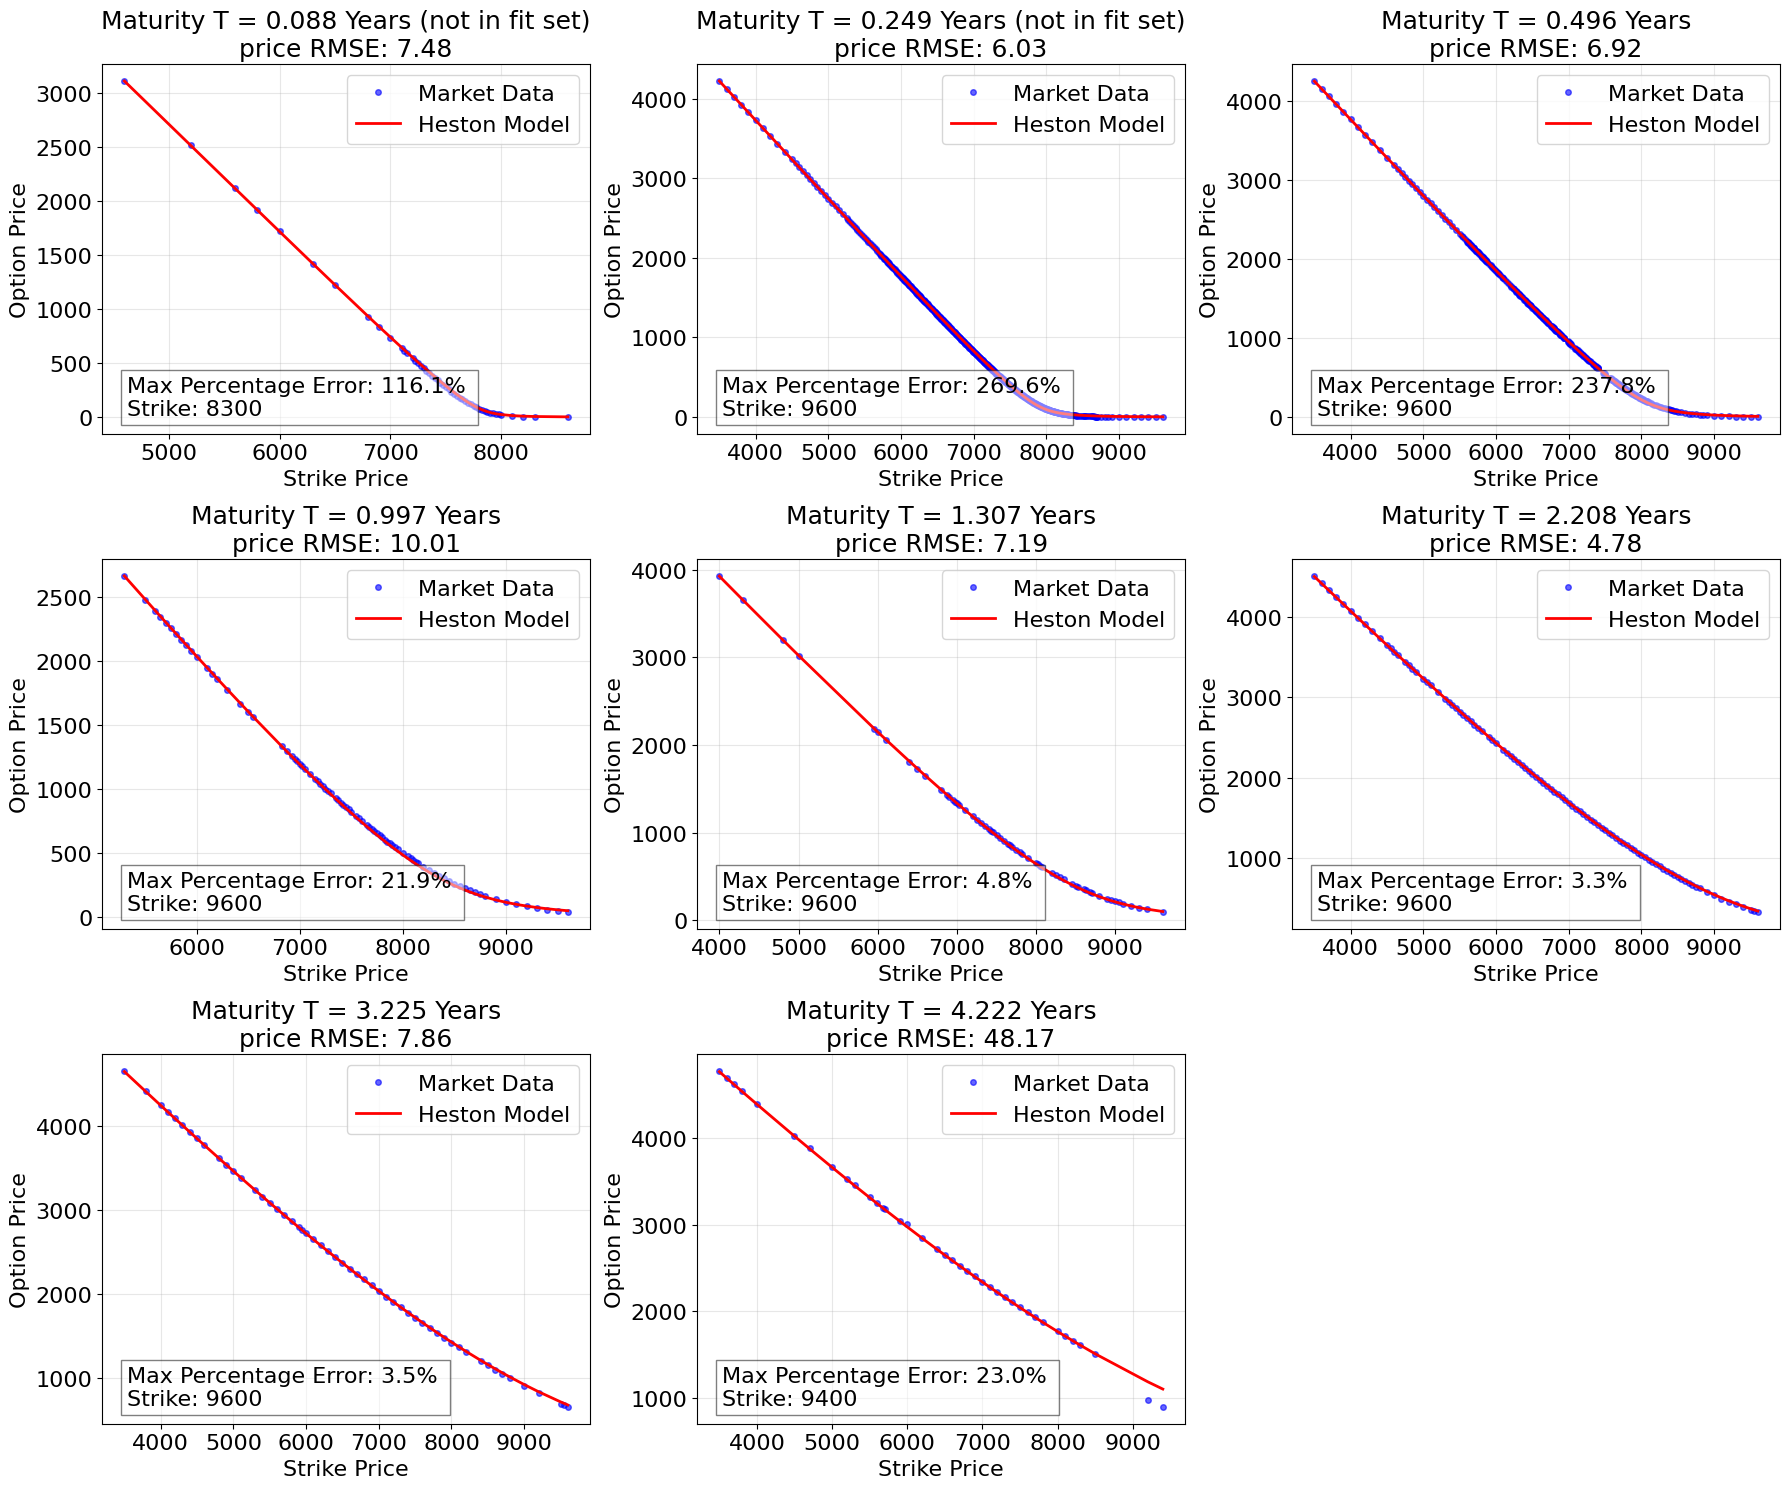

In [14]:
def plot_calibration_results(calibrator, optimal_params):
    """
    Plots Market vs. Heston Model prices for each maturity in the calibrator.

    Args:
        calibrator: The HestonFFTCalibrator instance.
        optimal_params: The calibrated parameters [kappa, theta, sigma, rho, v0].
    """
    # Generate all model prices using the optimal parameters
    all_model_prices = calibrator.price_surface(optimal_params)

    unique_Ts = [b['T'] for b in calibrator.data_batches]
    n_plots = len(unique_Ts)
    cols = 3
    rows = (n_plots + cols - 1) // cols  # Ceiling division

    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = axes.flatten()

    current_idx = 0

    for i, batch in enumerate(calibrator.data_batches):
        T = batch['T']
        strikes = batch['strikes']
        market_prices = batch['market_prices']
        n_points = len(strikes)

        # Slice the correct subset of model prices for this maturity
        model_subset = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Calculate local RMSE for this maturity
        rmse = np.sqrt(np.mean((model_subset - market_prices)**2))

        ax = axes[i]
        ax.plot(strikes, market_prices, 'bo', label='Market Data', alpha=0.6, markersize=4)
        ax.plot(strikes, model_subset, 'r-', label='Heston Model', linewidth=2)
        pct_error = (model_subset - market_prices) / (market_prices + 1e-5) * 100 # Avoid division by zero for deep OTM
        max_err = np.max(np.abs(pct_error)) # Add a text annotation for max error
        ax.text(0.05, 0.05, f"Max Percentage Error: {max_err:.1f}% \nStrike: {round(strikes[np.argmax(np.abs(pct_error))])}", transform=ax.transAxes,
                fontsize=16, bbox=dict(facecolor='white', alpha=0.5))

        tag = '' if T >= CALIB_MIN_T else ' (not in fit set)'
        ax.set_title(f"Maturity T = {T:.3f} Years{tag}\nprice RMSE: {rmse:.2f}", fontsize=18)
        ax.set_xlabel("Strike Price", fontsize=16)
        ax.set_ylabel("Option Price", fontsize=16)
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=16)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


plot_calibration_results(calibrator_full, result.x)   # all 8 expiries; 1M and 3M are out of sample

In [15]:
def analyze_calibration_results(result):
    kappa, theta, sigma, rho, v0 = result.x

    print("\nHeston Calibration Diagnosis")
    print(f"Calibrated parameters: kappa={kappa:.4f}, theta={theta:.4f}, sigma={sigma:.4f}, rho={rho:.4f}, v0={v0:.4f}")
    print(f"Objective (weighted IV RMSE): {100*result.fun:.3f} vol points\n")

    print(f"Mean reversion, kappa:  {kappa:.4f}")
    print(f"Long-Term volatility, sqrt(theta):  {np.sqrt(theta):.2%}")
    print(f"Vol-of-Vol, sigma:  {sigma:.4f}")
    print(f"Correlation between Spot and Vol, rho:  {rho:.4f}")
    print(f"Initial volatility, sqrt(v0):  {np.sqrt(v0):.2%}")


    warnings = []

    print("\nFeller condition check")
    # Feller condition check
    lhs = 2 * kappa * theta
    rhs = sigma ** 2

    if lhs > rhs:
        print(f"Feller condition satisfied ({lhs:.4f} > {rhs:.4f})")
    else:
        print(f"Feller condition violated ({lhs:.4f} < {rhs:.4f})")
        print("Variance will hit zero. Use Full Truncation in Monte Carlo.")
        if rhs > 0 and (lhs / rhs) < 0.1:
            warnings.append("Severe Feller violation. Process unstable.")


    # Parameter checks
    print("\n\nParameter checks")
    # Kappa
    if kappa > 10:
        print(f"Kappa is high ({kappa:.2f})")
        warnings.append("High kappa. Fitting short-term noise?")
    elif kappa < 0.5:
        print(f"Kappa is low ({kappa:.2f})")
    else:
        print(f"Kappa is normal ({kappa:.2f})")

    # Sigma
    if sigma > 1.5:
        print(f"Sigma is high ({sigma:.2f})")
        warnings.append("High sigma. High risk of Feller violation instability.")
    elif sigma < 0.01:
        warnings.append("Sigma near zero.")
    else:
        print(f"Sigma is normal ({sigma:.2f})")

    # Rho
    if rho <= -0.99:
        print(f"Rho pinned at lower bound ({rho:.4f})")
        warnings.append("Rho pinned at -1. Check if deep OTM puts are expensive.")
    elif rho >= 0:
        print(f"Rho is positive ({rho:.4f})")
        warnings.append("Positive rho. Unusual for equity.")
    else:
        print(f"Rho is normal ({rho:.2f})")

    # Term structure
    vol_long = np.sqrt(theta)
    vol_curr = np.sqrt(v0)
    if vol_long > vol_curr * 1.5:
        print(f"Upward vol term structure (spot {vol_curr:.1%} -> long {vol_long:.1%})")
    elif vol_curr > vol_long * 1.5:
        print(f"Downward vol term structure (spot {vol_curr:.1%} -> long {vol_long:.1%})")
    else:
        print(f"Flat/stable vol term structure")

    if warnings:
        print("\nWarnings detected:")
        for w in warnings:
            print(f"- {w}")
    else:
        print("\nCalibration looks healthy.")

analyze_calibration_results(result)


Heston Calibration Diagnosis
Calibrated parameters: kappa=2.8737, theta=0.0527, sigma=1.5258, rho=-0.6096, v0=0.0247
Objective (weighted IV RMSE): 0.541 vol points

Mean reversion, kappa:  2.8737
Long-Term volatility, sqrt(theta):  22.95%
Vol-of-Vol, sigma:  1.5258
Correlation between Spot and Vol, rho:  -0.6096
Initial volatility, sqrt(v0):  15.70%

Feller condition check
Feller condition violated (0.3027 < 2.3281)
Variance will hit zero. Use Full Truncation in Monte Carlo.


Parameter checks
Kappa is normal (2.87)
Sigma is high (1.53)
Rho is normal (-0.61)
Flat/stable vol term structure

Warnings detected:
- High sigma. High risk of Feller violation instability.


In [16]:
# # Input Parameters
S_REF = S0 # pricing using today's price as reference

# Unpack Heston parameters: kappa, theta, sigma, rho, v0
params = result.x

# Simulation horizon = final valuation date
T_max_years = OBS_TIMES[-1]

# Initialize pricer with curve functions; QE scheme by default
pricer = HestonAutocallPricer(
    S0=S0,
    S_ref=S_REF,
    r_curve_func=rate_curve_func, # Pass the bootstrapped function
    q_curve_func=dividend_curve_func,
    params=params,
    scheme='qe'
)

# Run simulation: daily steps with the observation dates inserted exactly, fixed seed
MC_SEED = 42
pricer.run_simulation(T_max=T_max_years, steps_per_year=252, n_paths=50000, obs_times=OBS_TIMES, seed=MC_SEED)

price, price_principal, price_coupon, price_put = pricer.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE)

print(f"\nFair Value: ${price:.2f}  (Monte Carlo s.e. {pricer.std_error:.2f})")
print(f"Percentage: {(price/1000)*100:.2f}%")
print(f"Expected life: {pricer.expected_life:.2f} years")
oc = pricer.outcomes
print(f"Autocall probability by date: {np.round(oc['call_prob_by_date'], 3)}")
print(f"Reach maturity: {oc['prob_reach_maturity']:.1%}  |  bonus (>=70%): {oc['prob_bonus_at_maturity']:.1%}  |  "
      f"par (60-70%): {oc['prob_safe_zone']:.1%}  |  knock-in (<60%): {oc['prob_knock_in']:.1%}, "
      f"mean final level given KI {oc['mean_perf_given_ki']:.1%}")
print(f"Zero-variance share of simulated days: {pricer.zero_variance_frac:.1%}")

print("\nProduct terms")
print(PRODUCT_PARAMS)


Simulation complete (qe): 50000 paths over 4.01 years (1017 steps), zero-variance share 41.9%.
Autocallable note price: 975.40 (MC s.e. 0.70),             
Principal component: 928.69,             
Coupon component: 71.62,             
Put risk component (short down-and-in put): -24.91

Fair Value: $975.40  (Monte Carlo s.e. 0.70)
Percentage: 97.54%
Expected life: 1.57 years
Autocall probability by date: [0.7   0.078 0.039 0.024 0.017 0.013]
Reach maturity: 13.0%  |  bonus (>=70%): 6.5%  |  par (60-70%): 1.6%  |  knock-in (<60%): 4.9%, mean final level given KI 38.0%
Zero-variance share of simulated days: 41.9%

Product terms
{'full_schedule': ['2027-10-01', '2028-04-01', '2028-10-01', '2029-04-02', '2029-10-02', '2030-04-03', '2030-10-03'], 'coupon_step': 0.03, 'barrier_redemption': 0.7, 'barrier_knock_in': 0.6, 'exit_bonus': 0.24, 'nominal': 1000, 'payment_lag_days': 7}


### Validation
Independent checks of the numerics, so that any remaining misfit is the model, not the code.
1. **Characteristic function:** $\phi(-i) = e^{(r-q)T}$ (evaluated at $u=-i+\varepsilon$ to avoid the removable singularity).
2. **FFT + spline vs direct quadrature** of the same Lewis integral.
3. **Martingale check:** $E[S_t]/F(t) = 1$ on the simulated paths.
4. **Vanilla repricing:** European calls from the Monte Carlo paths vs the FFT pricer, at 1Y and 4Y.
5. **Step-size convergence:** Euler vs QE at 12, 52 and 252 steps per year.


In [17]:
# 1. Forward check on the characteristic function
print("Forward check phi(-i) vs exp((r-q)T):")
for b in calibrator_full.data_batches:
    rT = calibrator_full.r_curve(b['T'])
    phi = calibrator_full._heston_char_func(np.array([-1j + 1e-7]), b['T'], rT, b['q'], params)[0]
    print(f"  T={b['T']:.3f}: phi={phi.real:.8f}  target={np.exp((rT - b['q'])*b['T']):.8f}  diff={abs(phi.real-np.exp((rT-b['q'])*b['T'])):.1e}")

# 2. FFT + spline vs direct quadrature, 50% to 120% strikes
K_check = np.linspace(0.5, 1.2, 15) * S0
print("\nFFT+spline vs direct quadrature (max abs error in index points, and in vol points):")
for b in calibrator_full.data_batches:
    rT = calibrator_full.r_curve(b['T'])
    p_fft = calibrator_full.price_calls(params, b['T'], K_check, b['q'])
    p_quad = calibrator_full.price_calls_quadrature(params, b['T'], K_check, b['q'])
    iv_fft = implied_vol_call_vec(p_fft, S0, K_check, b['T'], rT, b['q'])
    iv_quad = implied_vol_call_vec(p_quad, S0, K_check, b['T'], rT, b['q'])
    print(f"  T={b['T']:.3f}: {np.max(np.abs(p_fft - p_quad)):.2e} pts, {100*np.max(np.abs(iv_fft - iv_quad)):.2e} vol pts")


Forward check phi(-i) vs exp((r-q)T):
  T=0.088: phi=1.00324510  target=1.00324510  diff=0.0e+00
  T=0.249: phi=1.00913506  target=1.00913506  diff=2.2e-16
  T=0.496: phi=1.01907655  target=1.01907655  diff=2.2e-16
  T=0.997: phi=1.04183557  target=1.04183557  diff=0.0e+00
  T=1.307: phi=1.05723135  target=1.05723135  diff=2.2e-16
  T=2.208: phi=1.10130556  target=1.10130556  diff=4.4e-16
  T=3.225: phi=1.15432583  target=1.15432583  diff=6.7e-16
  T=4.222: phi=1.20877539  target=1.20877539  diff=1.1e-15

FFT+spline vs direct quadrature (max abs error in index points, and in vol points):
  T=0.088: 1.61e-02 pts, 7.21e-02 vol pts
  T=0.249: 6.36e-02 pts, 5.12e-03 vol pts
  T=0.496: 2.67e-02 pts, 1.29e-03 vol pts
  T=0.997: 4.30e-03 pts, 1.48e-04 vol pts
  T=1.307: 1.87e-03 pts, 5.88e-05 vol pts
  T=2.208: 2.03e-04 pts, 8.31e-06 vol pts
  T=3.225: 1.16e-04 pts, 5.81e-06 vol pts
  T=4.222: 1.02e-04 pts, 4.63e-06 vol pts


In [18]:
# 3. Martingale check on the pricing paths
print("Martingale check E[S_t]/F(t) - 1 (should be 0 within ~2 s.e.):")
display(pricer.martingale_check([0.25, 1.0, 2.0, 3.0, T_max_years]).round(5))

# 4. Vanilla repricing: Monte Carlo (same paths as the note) vs FFT
K_van = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1]) * S0
tables = []
for T_chk in [OBS_TIMES[0], T_max_years]:
    t_grid = pricer.time_grid[pricer._get_time_index(T_chk)]
    mc, se = pricer.mc_vanilla_calls(T_chk, K_van)
    fft = calibrator_full.price_calls(params, t_grid, K_van, dividend_curve_func(t_grid))
    tables.append(pd.DataFrame({'T': round(t_grid, 3), 'K/S0': K_van / S0, 'MC call': mc, 'MC s.e.': se,
                                'FFT call': fft, '(MC-FFT)/s.e.': (mc - fft) / se}))
vanilla_table = pd.concat(tables, ignore_index=True)
print("\nVanilla repricing, MC vs FFT:")
display(vanilla_table.round(3))
print(f"Largest |MC-FFT| in standard errors: {vanilla_table['(MC-FFT)/s.e.'].abs().max():.2f}")


Martingale check E[S_t]/F(t) - 1 (should be 0 within ~2 s.e.):


,T,E[S_t]/F(t) - 1,s.e.
0,0.24994,0.00002,0.00037
1,0.99976,-0.00099,0.00080
2,1.99953,-0.00184,0.00116
3,2.99929,-0.00261,0.00144
4,4.01096,-0.00183,0.00169



Vanilla repricing, MC vs FFT:


,T,K/S0,MC call,MC s.e.,FFT call,(MC-FFT)/s.e.
0,1.003,0.6,3284.255,5.568,3290.718,-1.161
1,1.003,0.7,2580.190,5.227,2586.293,-1.168
2,1.003,0.8,1896.189,4.770,1902.830,-1.392
3,1.003,0.9,1249.460,4.155,1256.044,-1.584
4,1.003,1.0,675.294,3.361,681.081,-1.722
5,1.003,1.1,260.028,2.419,263.656,-1.500
6,4.011,0.6,3887.154,11.666,3898.878,-1.005
7,4.011,0.7,3334.457,11.179,3344.594,-0.907
8,4.011,0.8,2807.928,10.597,2816.759,-0.833
9,4.011,0.9,2313.851,9.921,2321.282,-0.749


Largest |MC-FFT| in standard errors: 1.72


In [19]:
# 5. Step-size convergence: Euler (full truncation) vs QE, same seed and path count
rows = []
K_conv = np.array([0.6, 1.0]) * S0
for spy in [12, 52, 252]:
    for scheme in ['euler', 'qe']:
        p_tmp = HestonAutocallPricer(S0, S_REF, rate_curve_func, dividend_curve_func, params, scheme=scheme)
        p_tmp.run_simulation(T_max_years, steps_per_year=spy, n_paths=50000, obs_times=OBS_TIMES, seed=MC_SEED, verbose=False)
        px_tmp = p_tmp.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)[0]
        t_grid = p_tmp.time_grid[p_tmp._get_time_index(T_max_years)]
        mc, se = p_tmp.mc_vanilla_calls(T_max_years, K_conv)
        fft = calibrator_full.price_calls(params, t_grid, K_conv, dividend_curve_func(t_grid))
        rows.append({'steps/yr': spy, 'scheme': scheme, 'note price': px_tmp, 'note s.e.': p_tmp.std_error,
                     '4Y 60% call MC-FFT': mc[0] - fft[0], '(in s.e.)': (mc[0] - fft[0]) / se[0],
                     '4Y ATM call MC-FFT': mc[1] - fft[1], '(in s.e.) ': (mc[1] - fft[1]) / se[1],
                     'zero-var share': p_tmp.zero_variance_frac})
conv_table = pd.DataFrame(rows)
display(conv_table.round(3))
del p_tmp


,steps/yr,scheme,note price,note s.e.,4Y 60% call MC-FFT,(in s.e.),4Y ATM call MC-FFT,(in s.e.),zero-var share
0,12,euler,970.052,0.740,21.252,1.758,35.696,3.716,0.537
1,12,qe,977.049,0.677,10.270,0.877,8.932,0.967,0.613
2,52,euler,974.714,0.706,11.947,1.024,6.918,0.751,0.465
3,52,qe,976.833,0.687,6.165,0.531,-0.129,-0.014,0.513
4,252,euler,974.384,0.708,-10.600,-0.908,-5.148,-0.561,0.382
5,252,qe,975.400,0.696,-11.724,-1.005,-5.831,-0.637,0.419


### Validation, continued: limit case and path convergence
6. **Limit case.** With a single observation at maturity (no autocall) and the knock-in at zero, the note is a zero-coupon bond plus a 24% digital at 70%, which the FFT prices in closed form. With the coupon and bonus also at zero it is the bond alone.
7. **Path convergence.** Same scheme and grid, 25k to 200k paths: the price must stay inside one standard error and the standard error must halve when the paths quadruple.


In [20]:
# 6. Limit case: no autocall (single observation at maturity), knock-in at zero -> bond + digital in closed form
limit_params = dict(PRODUCT_PARAMS); limit_params['full_schedule'] = [PRODUCT_SCHEDULE[-1]]; limit_params['barrier_knock_in'] = 0.0
mc_limit = pricer.price_structure(**limit_params, pricing_date=PRICING_DATE, verbose=False); se_limit = pricer.std_error
T_fin = (datetime.strptime(PRODUCT_SCHEDULE[-1], "%Y-%m-%d") - PRICING_DATE).days / 365; t_pay = T_fin + PRODUCT_PARAMS['payment_lag_days'] / 365
df_pay = np.exp(-rate_curve_func(t_pay) * t_pay); t_grid = pricer.time_grid[pricer._get_time_index(T_fin)]
K_b = PRODUCT_PARAMS['barrier_redemption'] * S_REF; h = 0.002
c_pair = calibrator_full.price_calls(params, t_grid, [K_b * (1 - h), K_b * (1 + h)], dividend_curve_func(t_grid))
p_digital = (c_pair[0] - c_pair[1]) / (2 * h * K_b) / np.exp(-rate_curve_func(t_grid) * t_grid)      # P(S_T >= 70%) under the calibrated model
closed = PRODUCT_PARAMS['nominal'] * df_pay * (1 + PRODUCT_PARAMS['exit_bonus'] * p_digital)
print(f"Limit case (no autocall, KI = 0): MC {mc_limit[0]:.2f} (s.e. {se_limit:.2f}) vs closed form {closed:.2f}; "
      f"difference {mc_limit[0] - closed:+.2f} = {(mc_limit[0] - closed) / se_limit:+.2f} s.e.  [P(S_T >= 70%): FFT {p_digital:.4f}, MC {pricer.outcomes['prob_bonus_at_maturity']:.4f}]")
bond_params = dict(limit_params); bond_params['coupon_step'] = 0.0; bond_params['exit_bonus'] = 0.0
print(f"Pure bond limit: MC {pricer.price_structure(**bond_params, pricing_date=PRICING_DATE, verbose=False)[0]:.4f} vs nominal x DF {PRODUCT_PARAMS['nominal'] * df_pay:.4f}")

# 7. Path convergence (same seed, scheme and grid)
rows = []
for n_p in [25000, 50000, 100000, 200000]:
    p_tmp = HestonAutocallPricer(S0, S_REF, rate_curve_func, dividend_curve_func, params, scheme='qe')
    p_tmp.run_simulation(T_max_years, steps_per_year=252, n_paths=n_p, obs_times=OBS_TIMES, seed=MC_SEED, verbose=False)
    px_tmp = p_tmp.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)[0]
    rows.append({'paths': n_p, 'price': px_tmp, 's.e.': p_tmp.std_error, 's.e. x sqrt(paths)': p_tmp.std_error * np.sqrt(n_p)})
    del p_tmp
display(pd.DataFrame(rows).round(3))


Limit case (no autocall, KI = 0): MC 986.23 (s.e. 0.31) vs closed form 986.78; difference -0.55 = -1.79 s.e.  [P(S_T >= 70%): FFT 0.8601, MC 0.8573]
Pure bond limit: MC 817.9415 vs nominal x DF 817.9415


,paths,price,s.e.,s.e. x sqrt(paths)
0,25000,976.406,0.970,153.370
1,50000,975.400,0.696,155.603
2,100000,976.338,0.487,153.915
3,200000,975.765,0.347,155.233


### Validation, continued: independent implementation (finite differences)
8. **PDE benchmark.** The same note on the 2-D Heston PDE in (log S, V): Craig-Sneyd ADI, log-spot grid with nodes on the 60%, 70% and 100% barriers, sinh-spaced variance grid, the autocall as jump conditions on the observation dates, Rannacher restarts after each discontinuity, the same term-structure drift, discounting and payment lag as the Monte Carlo. Each leg is solved as its own PDE, so the decomposition can be compared too. Also the no-autocall / no-knock-in limit against the closed form, and the delta and gamma read off the grid.


In [21]:
import time
from pde_heston import HestonADISolver, price_autocall_pde
pde_solver = HestonADISolver(params)
pde_vals = {}
t0 = time.perf_counter()
for leg in ['total', 'principal', 'coupon', 'put']:
    pde_vals[leg], U_pde, _ = price_autocall_pde(params, S0, rate_curve_func, dividend_curve_func, OBS_TIMES, leg=leg, solver=pde_solver,
                                                 coupon_step=PRODUCT_PARAMS['coupon_step'], exit_bonus=PRODUCT_PARAMS['exit_bonus'],
                                                 payment_lag_days=PRODUCT_PARAMS['payment_lag_days'])
    if leg == 'total': U_total = U_pde
pde_secs = time.perf_counter() - t0
mc_vals = {'total': price, 'principal': price_principal, 'coupon': price_coupon, 'put': price_put}
pricer.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)   # restore the note's own s.e. (the limit-case calls overwrote it)
mc_se = pricer.std_error
pde_table = pd.DataFrame({'PDE (ADI, %d x %d grid)' % (pde_solver.nx, pde_solver.nv): pde_vals, 'Monte Carlo (50k paths)': mc_vals})
pde_table['difference'] = pde_table.iloc[:, 0] - pde_table.iloc[:, 1]
pde_table['in MC s.e.'] = pde_table['difference'] / mc_se
display(pde_table.round(3))
print(f"PDE: {pde_secs/4:.1f} s per solve. Legs add up: {pde_vals['principal'] + pde_vals['coupon'] + pde_vals['put']:.3f} vs total {pde_vals['total']:.3f}")
v_lim_pde, _, _ = price_autocall_pde(params, S0, rate_curve_func, dividend_curve_func, np.array([OBS_TIMES[-1]]), barrier_knock_in=0.0, solver=pde_solver,
                                     exit_bonus=PRODUCT_PARAMS['exit_bonus'], payment_lag_days=PRODUCT_PARAMS['payment_lag_days'])
print(f"Limit case (no autocall, KI = 0): PDE {v_lim_pde:.2f} vs closed form {closed:.2f} vs MC {mc_limit[0]:.2f}")
d_pde, g_pde = pde_solver.delta_gamma_at(U_total, S0)
print(f"PDE Greeks at spot (client seat): delta {d_pde:+.4f} per index point = {100*d_pde*S0/PRODUCT_PARAMS['nominal']:.1f}% of notional as an index hedge; cash gamma per 1% move {g_pde*S0**2/100:+.2f}")


,"PDE (ADI, 509 x 80 grid)",Monte Carlo (50k paths),difference,in MC s.e.
total,976.188,975.400,0.788,1.132
principal,929.340,928.695,0.645,0.927
coupon,71.304,71.616,-0.312,-0.448
put,-24.457,-24.911,0.455,0.653


PDE: 7.2 s per solve. Legs add up: 976.188 vs total 976.188


Limit case (no autocall, KI = 0): PDE 986.91 vs closed form 986.78 vs MC 986.23
PDE Greeks at spot (client seat): delta +0.0204 per index point = 15.7% of notional as an index hedge; cash gamma per 1% move -12.10


### Price attribution: what moved the price from v1 to v2
Each row changes one thing on the same random numbers, in the order the changes were made.

In [22]:
attrib_rows = []
def _px(params_, scheme, lag):
    p_tmp = HestonAutocallPricer(S0, S_REF, rate_curve_func, dividend_curve_func, params_, scheme=scheme)
    p_tmp.run_simulation(T_max_years, steps_per_year=252, n_paths=50000, obs_times=OBS_TIMES, seed=MC_SEED, verbose=False)
    pp = dict(PRODUCT_PARAMS); pp['payment_lag_days'] = lag
    out = p_tmp.price_structure(**pp, pricing_date=PRICING_DATE, verbose=False)
    return out, p_tmp.std_error, p_tmp.outcomes

steps = [("v1 method parameters, Euler, no payment lag", PARAMS_V1, 'euler', 0),
         ("+ QE scheme",                            PARAMS_V1, 'qe',    0),
         ("+ v2 calibration (vol-space, filtered)", params,    'qe',    0),
         ("+ 7-day payment lag  (= v2 price)",      params,    'qe',    7)]
prev = None
for label, p_, sch, lag in steps:
    (tot, pri, cou, put), se_, oc_ = _px(p_, sch, lag)
    attrib_rows.append({'step': label, 'price': tot, 'change': (tot - prev) if prev is not None else np.nan,
                        's.e.': se_, 'principal': pri, 'coupons': cou, 'put': put,
                        'P(call @1Y)': oc_['call_prob_by_date'][0], 'P(KI)': oc_['prob_knock_in'], 'life (y)': oc_['expected_life']})
    prev = tot
attribution = pd.DataFrame(attrib_rows)
display(attribution.round(3))


,step,price,change,s.e.,principal,coupons,put,P(call @1Y),P(KI),life (y)
0,"v1 method parameters, Euler, no payment lag",974.894,NaN,0.712,929.409,71.598,-26.114,0.698,0.051,1.577
1,+ QE scheme,975.389,0.495,0.706,929.369,71.678,-25.658,0.696,0.051,1.578
2,"+ v2 calibration (vol-space, filtered)",976.327,0.938,0.697,929.577,71.685,-24.935,0.700,0.049,1.573
3,+ 7-day payment lag (= v2 price),975.400,-0.927,0.696,928.695,71.616,-24.911,0.700,0.049,1.573


In [23]:
# Discount-curve sensitivity: the Treasury curve stands in for SOFR OIS. Shift the discounting by -25 bp with the
# forward held fixed (r and q move together, so the paths are unchanged and only the discount factors move).
_r_orig = pricer.r_curve_func
pricer.r_curve_func = lambda t: _r_orig(t) - 0.0025
px_shift = pricer.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)[0]
pricer.r_curve_func = _r_orig
print(f"Note value with discounting 25 bp lower (forward fixed): {px_shift:.2f} vs {price:.2f}, i.e. {px_shift - price:+.2f} per 1,000")
print(f"Rule of thumb: about {(px_shift - price)/25*10:+.2f} per 1,000 for every 10 bp the true OIS curve sits below Treasuries.")


Note value with discounting 25 bp lower (forward fixed): 979.07 vs 975.40, i.e. +3.67 per 1,000
Rule of thumb: about +1.47 per 1,000 for every 10 bp the true OIS curve sits below Treasuries.


### Fair coupon
On a desk the coupon is solved, not guessed: find the coupon per period at which the note is worth the target price, using the same paths for every trial so the price is a smooth function of the coupon. The final bonus stays at 8 x coupon as in the term sheet.

Fair coupon per semester at par (100%):            4.031%
Fair coupon per semester at 98.75% (1.25% margin):  3.507%
Reference: the note was priced with 3.00% per semester (original BNP note: 4.52% in March 2023).


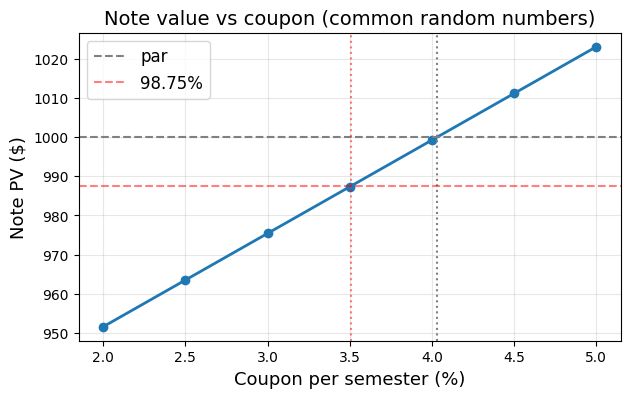

In [24]:
c_par = pricer.solve_fair_coupon(PRODUCT_PARAMS, target_price=1000.0, pricing_date=PRICING_DATE)
c_margin = pricer.solve_fair_coupon(PRODUCT_PARAMS, target_price=987.5, pricing_date=PRICING_DATE)
print(f"Fair coupon per semester at par (100%):            {c_par:.3%}")
print(f"Fair coupon per semester at 98.75% (1.25% margin):  {c_margin:.3%}")
print(f"Reference: the note was priced with 3.00% per semester (original BNP note: 4.52% in March 2023).")

# Price as a function of the coupon on the same paths (linear because every coupon scales with c)
c_grid = np.linspace(0.02, 0.05, 7)
px_grid = [pricer.price_structure(**{**PRODUCT_PARAMS, 'coupon_step': c, 'exit_bonus': 8*c}, pricing_date=PRICING_DATE, verbose=False)[0] for c in c_grid]
plt.figure(figsize=(7, 4))
plt.plot(100*c_grid, px_grid, 'o-', lw=2)
plt.axhline(1000, color='gray', ls='--', label='par'); plt.axvline(100*c_par, color='gray', ls=':')
plt.axhline(987.5, color='red', ls='--', alpha=0.5, label='98.75%'); plt.axvline(100*c_margin, color='red', ls=':', alpha=0.5)
plt.xlabel('Coupon per semester (%)', fontsize=13); plt.ylabel('Note PV ($)', fontsize=13)
plt.title('Note value vs coupon (common random numbers)', fontsize=14); plt.grid(alpha=0.3); plt.legend(fontsize=12)
plt.show()


### Hedging costs and structure sensitivities
What the desk reserves against, on the same paths (common random numbers, 100,000 QE paths; the 'vs base' column is the paired difference with its own standard error). Client-seat values; the desk is the mirror image.
- **Barrier shifts**: each barrier moved ±1% (relative), and all three moved 1% against the desk at once (autocall 99%, bonus 69.3%, knock-in 59.4%), the usual barrier-shift reserve.
- **Coupon**: the price is linear in the coupon on fixed paths; sensitivity per bp, and the fair coupon under the shifted barriers and under the spread overhedge.
- **Digitals as call / put spreads**: each digital replaced by a spread of width 1%, 2%, 5% on the side that is conservative for the desk (call spread below the autocall and bonus levels, put spread below the knock-in); the difference to the digital is the overhedge cost.
- **Conventions**: payment lag, and the knock-in observed daily instead of at maturity.
- **Market inputs** re-simulated with the same seed: dividend yield ±10 bp, observation dates ±5 days, rates +10 bp (discounting only).
- **Vega-hedge crossing cost** from the quote widths in vol.


In [25]:
from scipy import optimize
# ---- Hedging costs and structure sensitivities (client seat values; desk = mirror image) ----
# Everything on common random numbers: one QE simulation, the payoff rules varied; re-simulation with the same seed where the dynamics change.
N_HEDGE = 100000
pr_h = HestonAutocallPricer(S0, S_REF, rate_curve_func, dividend_curve_func, params, scheme='qe')
pr_h.run_simulation(T_max_years, steps_per_year=252, n_paths=N_HEDGE, obs_times=OBS_TIMES, seed=MC_SEED, verbose=False)

def note_pv(pricer_, obs_times, ac=1.0, bonus_b=0.70, ki=0.60, coupon=0.03, bonus=None, lag_days=7, h_ac=0.0, h_bonus=0.0, h_ki=0.0, american_ki=False, nominal=1000.0, rate_fn=None):
    """Per-path PV of the note. h_* > 0 replaces the digital at that barrier by a ramp of relative width h on the side
    that is conservative for the desk (call spread below the autocall and bonus levels, put spread below the knock-in)."""
    bonus = 8 * coupon if bonus is None else bonus
    rate_curve_func = rate_fn if rate_fn is not None else pricer_.r_curve_func
    Sp = pricer_.S_paths / S_REF; n_ = Sp.shape[1]; lag = lag_days / 365.0
    idxs = [pricer_._get_time_index(t) for t in obs_times]
    alive = np.ones(n_); pv_ = np.zeros(n_)
    for k, (t, i) in enumerate(zip(obs_times[:-1], idxs[:-1])):
        s = Sp[i]
        w = np.clip((s - ac * (1 - h_ac)) / (ac * h_ac), 0, 1) if h_ac > 0 else (s >= ac).astype(float)
        tp = t + lag; df = np.exp(-rate_curve_func(tp) * tp)
        pv_ += alive * w * nominal * (1 + (k + 2) * coupon) * df; alive = alive * (1 - w)
    ST = Sp[idxs[-1]]; tp = obs_times[-1] + lag; df = np.exp(-rate_curve_func(tp) * tp)
    wb = np.clip((ST - bonus_b * (1 - h_bonus)) / (bonus_b * h_bonus), 0, 1) if h_bonus > 0 else (ST >= bonus_b).astype(float)
    if american_ki:
        hit = (Sp[:idxs[-1] + 1].min(axis=0) < ki).astype(float)          # daily observation of the knock-in
        wk = hit * (ST < 1.0)
    else:
        wk = np.clip((ki - ST) / (ki * h_ki), 0, 1) if h_ki > 0 else (ST < ki).astype(float)
    final = nominal * (1 + bonus * wb) - nominal * wk * np.clip(1 - ST, 0, None)
    pv_ += alive * final * df
    return pv_

base_pv = note_pv(pr_h, OBS_TIMES); BASE = base_pv.mean(); BASE_SE = base_pv.std(ddof=1) / np.sqrt(N_HEDGE)
chk = pr_h.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)[0]
assert abs(BASE - chk) < 1e-6, (BASE, chk)
def diff(pv_alt, label, group):
    d = pv_alt - base_pv
    return {'group': group, 'change': label, 'price': pv_alt.mean(), 'vs base': d.mean(), 's.e. of difference': d.std(ddof=1) / np.sqrt(N_HEDGE)}
rows = []
# 1. barriers, ±1% relative, one at a time, then all three against the desk
for name, kw_dn, kw_up in [('autocall level 100%', dict(ac=0.99), dict(ac=1.01)), ('bonus barrier 70%', dict(bonus_b=0.693), dict(bonus_b=0.707)), ('knock-in 60%', dict(ki=0.594), dict(ki=0.606))]:
    rows.append(diff(note_pv(pr_h, OBS_TIMES, **kw_dn), f"{name} -1%", 'barriers')); rows.append(diff(note_pv(pr_h, OBS_TIMES, **kw_up), f"{name} +1%", 'barriers'))
rows.append(diff(note_pv(pr_h, OBS_TIMES, ac=0.99, bonus_b=0.693, ki=0.594), 'all three shifted 1% against the desk (autocall 99%, bonus 69.3%, KI 59.4%)', 'barriers'))
# 2. coupon: price is linear in the coupon on fixed paths (bonus = 8 x coupon)
for c in [0.029, 0.031]: rows.append(diff(note_pv(pr_h, OBS_TIMES, coupon=c), f"coupon {c:.1%} per semester (bonus 8x)", 'coupon'))
rows.append(diff(note_pv(pr_h, OBS_TIMES, coupon=0.031, bonus=0.24), 'coupon 3.1%, bonus held at 24%', 'coupon'))
coupon_dv = (note_pv(pr_h, OBS_TIMES, coupon=0.0301).mean() - BASE) / 1    # per 1 bp of coupon
def fair_c(**kw): return optimize.brentq(lambda c: note_pv(pr_h, OBS_TIMES, coupon=c, **kw).mean() - 1000.0, 0.0, 0.2)
# 3. digitals replaced by call / put spreads of width h, conservative side for the desk
for h in [0.01, 0.02, 0.05]:
    rows.append(diff(note_pv(pr_h, OBS_TIMES, h_ac=h), f"autocall digitals as call spreads, width {h:.0%}", 'digitals -> spreads'))
    rows.append(diff(note_pv(pr_h, OBS_TIMES, h_bonus=h), f"70% bonus digital as a call spread, width {h:.0%}", 'digitals -> spreads'))
    rows.append(diff(note_pv(pr_h, OBS_TIMES, h_ki=h), f"60% knock-in digital as a put spread, width {h:.0%}", 'digitals -> spreads'))
    rows.append(diff(note_pv(pr_h, OBS_TIMES, h_ac=h, h_bonus=h, h_ki=h), f"all digitals as spreads, width {h:.0%}", 'digitals -> spreads'))
# 4. payment lag and knock-in style
rows.append(diff(note_pv(pr_h, OBS_TIMES, lag_days=0), 'no payment lag', 'conventions')); rows.append(diff(note_pv(pr_h, OBS_TIMES, lag_days=14), 'payment lag 14 days', 'conventions'))
rows.append(diff(note_pv(pr_h, OBS_TIMES, american_ki=True), 'knock-in observed daily (American) instead of at maturity', 'conventions'))
# 5. dynamics re-simulated with the same seed: dividend yield, observation dates, rates
for dq, label in [(0.001, 'dividend yield +10 bp'), (-0.001, 'dividend yield -10 bp')]:
    p_ = HestonAutocallPricer(S0, S_REF, rate_curve_func, lambda t, dq=dq: dividend_curve_func(t) + dq, params, scheme='qe'); p_.run_simulation(T_max_years, 252, N_HEDGE, obs_times=OBS_TIMES, seed=MC_SEED, verbose=False)
    rows.append(diff(note_pv(p_, OBS_TIMES), label, 'market (re-simulated, same seed)')); del p_
for dd, label in [(5, 'all observation dates +5 days'), (-5, 'all observation dates -5 days')]:
    obs_s = OBS_TIMES + dd / 365.0; p_ = HestonAutocallPricer(S0, S_REF, rate_curve_func, dividend_curve_func, params, scheme='qe'); p_.run_simulation(obs_s[-1], 252, N_HEDGE, obs_times=obs_s, seed=MC_SEED, verbose=False)
    rows.append(diff(note_pv(p_, obs_s), label, 'market (re-simulated, same seed)')); del p_
r0_ = pr_h.r_curve_func; rows.append(diff(note_pv(pr_h, OBS_TIMES, rate_fn=lambda t: r0_(t) + 0.0010), 'rates +10 bp, discounting only (forward fixed)', 'market (re-simulated, same seed)'))
HEDGE = pd.DataFrame(rows).set_index(['group', 'change'])
print(f"Base on {N_HEDGE:,} paths: {BASE:.2f} (s.e. {BASE_SE:.2f}); the 'vs base' column is a common-random-number difference, with its own s.e.")
display(HEDGE.round(3))
print(f"Coupon sensitivity: {coupon_dv:+.3f} per 1 bp of semester coupon (bonus tied at 8x); fair coupon at par {fair_c():.3%}; "
      f"with all barriers 1% against the desk {fair_c(ac=0.99, bonus_b=0.693, ki=0.594):.3%}; with every digital a 2% spread {fair_c(h_ac=0.02, h_bonus=0.02, h_ki=0.02):.3%}")
# 6. vega-hedge bid-ask cost: the desk buys the vega it is short on the put leg in long-dated puts; cost = vega x half the quote width in vol
m4 = calibrator_full.flat_T > 4.0; k_ki = np.argmin(np.abs(calibrator_full.flat_K[m4] - 0.6 * S0)); half_spread = 50 * calibrator_full.vol_spread[m4][k_ki]   # vol pts
print(f"Vega-hedge crossing cost: put-leg vega about 0.39 per vol point (PDE) x half the 4.2Y 60% quote width ({half_spread:.1f} vol pts) = about {0.39*half_spread:.1f} per 1,000; "
      f"with 1Y–2Y puts instead (quotes 0.1–0.2 vol pts wide) about {0.39*0.1:.2f}")
del pr_h


Base on 100,000 paths: 976.34 (s.e. 0.49); the 'vs base' column is a common-random-number difference, with its own s.e.


price  \
group                            change                                                        
barriers                         autocall level 100% -1%                             977.259   
                                 autocall level 100% +1%                             975.347   
                                 bonus barrier 70% -1%                               976.570   
                                 bonus barrier 70% +1%                               976.103   
                                 knock-in 60% -1%                                    976.674   
                                 knock-in 60% +1%                                    976.052   
                                 all three shifted 1% against the desk (autocall...  977.803   
coupon                           coupon 2.9% per semester (bonus 8x)                 973.948   
                                 coupon 3.1% per semester (bonus 8x)                 978.729   
                                 coupon 3.1%, bonus held at 24%                      978.311   
digitals -> spreads              autocall digitals as call spreads, width 1%         976.821   
                                 70% bonus digital as a call spread, width 1%        976.451   
                                 60% knock-in digital as a put spread, width 1%      976.507   
                                 all digitals as spreads, width 1%                   977.098   
                                 autocall digitals as call spreads, width 2%         977.266   
                                 70% bonus digital as a call spread, width 2%        976.562   
                                 60% knock-in digital as a put spread, width 2%      976.662   
                                 all digitals as spreads, width 2%                   977.793   
                                 autocall digitals as call spreads, width 5%         978.632   
                                 70% bonus digital as a call spread, width 5%        976.889   
                                 60% knock-in digital as a put spread, width 5%      977.077   
                                 all digitals as spreads, width 5%                   979.803   
conventions                      no payment lag                                      977.266   
                                 payment lag 14 days                                 975.409   
                                 knock-in observed daily (American) instead of a...  967.839   
market (re-simulated, same seed) dividend yield +10 bp                               975.917   
                                 dividend yield -10 bp                               976.775   
                                 all observation dates +5 days                       975.111   
                                 all observation dates -5 days                       977.428   
                                 rates +10 bp, discounting only (forward fixed)      974.880   

                                                                                     vs base  \
group                            change                                                        
barriers                         autocall level 100% -1%                               0.921   
                                 autocall level 100% +1%                              -0.991   
                                 bonus barrier 70% -1%                                 0.232   
                                 bonus barrier 70% +1%                                -0.236   
                                 knock-in 60% -1%                                      0.336   
                                 knock-in 60% +1%                                     -0.286   
                                 all three shifted 1% against the desk (autocall...    1.465   
coupon                           coupon 2.9% per semester (bonus 8x)                  -2.390   
                                 coupon 3.1% per semes

Coupon sensitivity: +0.239 per 1 bp of semester coupon (bonus tied at 8x); fair coupon at par 3.990%; with all barriers 1% against the desk 3.942%; with every digital a 2% spread 3.942%
Vega-hedge crossing cost: put-leg vega about 0.39 per vol point (PDE) x half the 4.2Y 60% quote width (2.8 vol pts) = about 1.1 per 1,000; with 1Y–2Y puts instead (quotes 0.1–0.2 vol pts wide) about 0.04


### European call IV
Market IV vs Heston IV plots (IV from B-S formula). Sanity check for Heston calibration quality.

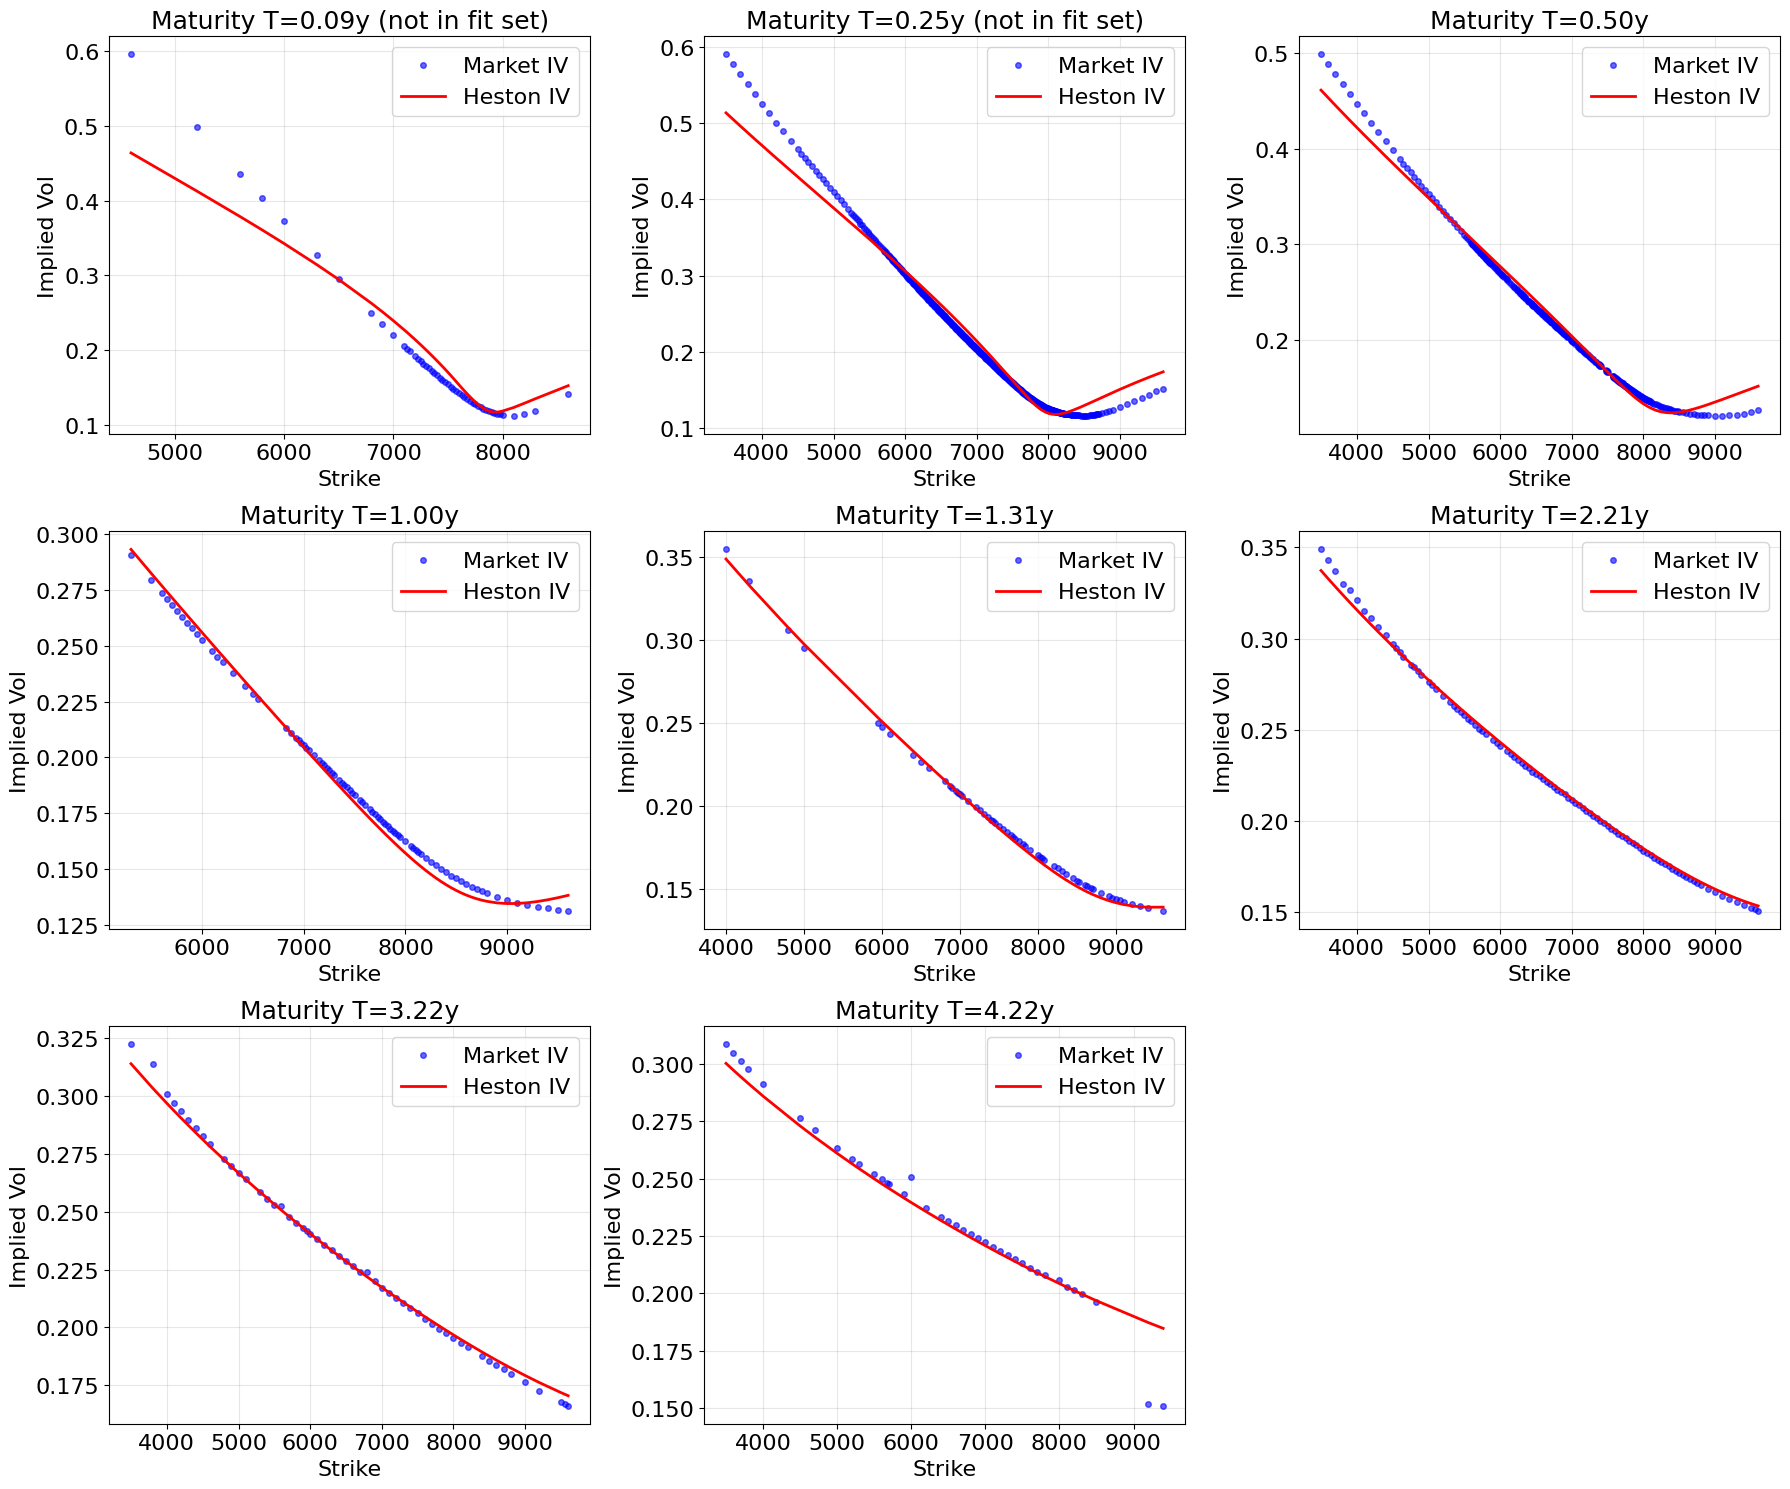

In [26]:
def bs_call(S, K, T, r, q, vol):
    d1 = (np.log(S/K) + (r - q + 0.5*vol*vol)*T) / (vol*np.sqrt(T))
    d2 = d1 - vol*np.sqrt(T)
    return S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

def implied_vol_call(C, S, K, T, r, q):
    # Safety: intrinsic value check
    intrinsic = max(S*np.exp(-q*T) - K*np.exp(-r*T), 0)
    if C <= intrinsic + 1e-5: # Add tiny buffer
        return np.nan
    try:
        # Solving BS(vol) - Price = 0
        return brentq(lambda vol: bs_call(S, K, T, r, q, vol) - C, 1e-6, 5.0)
    except:
        return np.nan

def plot_calibration_iv_smiles(calibrator, optimal_params):
    """
    Plots Market IV vs Heston IV using the calibrator instance.
    """
    # Get Heston model prices using the optimized params
    all_model_prices = calibrator.price_surface(optimal_params)

    # Iterate through batches to plot per maturity
    current_idx = 0

    # Setup subplot grid
    unique_Ts = [b['T'] for b in calibrator.data_batches]
    n_plots = len(unique_Ts)
    cols = 3
    rows = (n_plots + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = axes.flatten()

    for i, batch in enumerate(calibrator.data_batches):
        T = batch['T']
        strikes = batch['strikes']
        mkt_prices = batch['market_prices']
        qT = batch['q']

        # Get specific rate from your curve function
        rT = calibrator.r_curve(T)

        # Slice model prices corresponding to this batch
        n_points = len(strikes)
        hes_prices = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Calculate IVs using the SAME r and q for both Market and Heston
        mkt_ivs = []
        hes_ivs = []

        for k_i, m_p, h_p in zip(strikes, mkt_prices, hes_prices):
            # Market IV
            mkt_ivs.append(implied_vol_call(m_p, calibrator.S0, k_i, T, rT, qT))
            # Heston IV
            hes_ivs.append(implied_vol_call(h_p, calibrator.S0, k_i, T, rT, qT))

        # Plotting
        ax = axes[i]
        ax.plot(strikes, mkt_ivs, 'bo', label="Market IV", markersize=4, alpha=0.6)
        ax.plot(strikes, hes_ivs, 'r-', label="Heston IV", linewidth=2)

        tag = '' if T >= CALIB_MIN_T else ' (not in fit set)'
        ax.set_title(f"Maturity T={T:.2f}y{tag}", fontsize=18)
        ax.set_xlabel("Strike", fontsize=16)
        ax.set_ylabel("Implied Vol", fontsize=16)
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=16)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


plot_calibration_iv_smiles(calibrator_full, result.x)   # 1M and 3M are out of sample


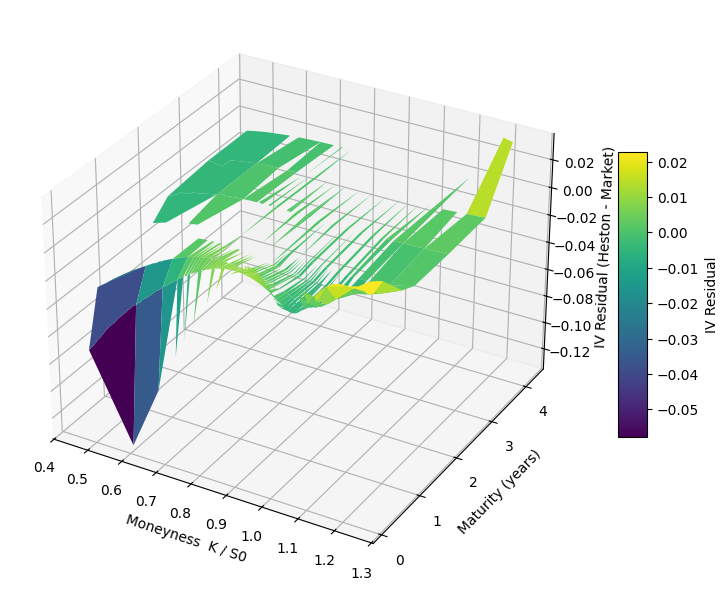

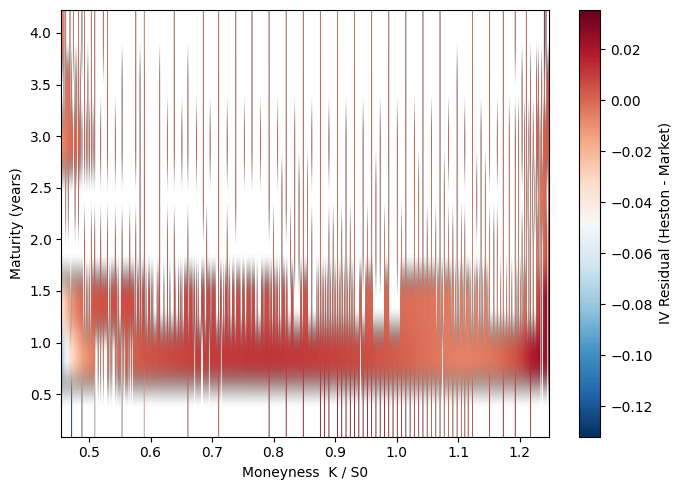

In [27]:
def compute_iv_residual_grid(calibrator, optimal_params):
    """
    Build a rectangular grid of IV residuals (Heston IV - Market IV)
    over (maturity, moneyness) using the existing 'calibrator' object.

    Returns
    -------
    maturity_grid : 1D np.array of maturities (years)
    moneyness_grid: 1D np.array of K / S0
    residuals     : 2D np.array [n_maturities, n_strikes] of IV residuals
                    (may contain np.nan where no data is available)
    """
    # Use existing pricing routine: prices for ALL market points
    all_model_prices = calibrator.price_surface(optimal_params)

    # Collect unique maturities and all unique strikes across batches
    batches = calibrator.data_batches
    unique_T = [b['T'] for b in batches]
    all_strikes = sorted({K for b in batches for K in b['strikes']})

    n_T = len(unique_T)
    n_K = len(all_strikes)

    maturity_grid  = np.array(unique_T)
    moneyness_grid = np.array(all_strikes) / calibrator.S0

    # Residuals matrix: Heston IV - Market IV (NaN where no point exists)
    residuals = np.full((n_T, n_K), np.nan)

    # Pre-build map from strike to column index for speed
    strike_to_idx = {K: j for j, K in enumerate(all_strikes)}

    current_idx = 0

    for i, batch in enumerate(batches):
        T       = batch['T']
        strikes = batch['strikes']
        mkt_px  = batch['market_prices']
        qT      = batch['q']
        rT      = calibrator.r_curve(T)

        n_points = len(strikes)
        hes_px   = all_model_prices[current_idx : current_idx + n_points]
        current_idx += n_points

        # Convert prices -> IV using existing implied_vol_call()
        mkt_iv = np.array([
            implied_vol_call(C=float(C), S=calibrator.S0, K=float(K), T=T, r=rT, q=qT)
            for C, K in zip(mkt_px, strikes)
        ])
        hes_iv = np.array([
            implied_vol_call(C=float(C), S=calibrator.S0, K=float(K), T=T, r=rT, q=qT)
            for C, K in zip(hes_px, strikes)
        ])

        # Fill residual matrix
        for K, iv_mkt, iv_hes in zip(strikes, mkt_iv, hes_iv):
            j = strike_to_idx[K]
            residuals[i, j] = iv_hes - iv_mkt

    return maturity_grid, moneyness_grid, residuals


def plot_residual_surface_3d(maturity_grid, moneyness_grid, residuals):
    """
    3D surface of IV residuals (Heston IV - Market IV).
    """
    # Build meshgrid
    T_grid, K_grid = np.meshgrid(maturity_grid, moneyness_grid, indexing='ij')
    Z = residuals.copy()

    # Mask NaNs if any
    Z_masked = np.ma.masked_invalid(Z)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    surf = ax.plot_surface(
        K_grid,          # x-axis: moneyness (K/S0)
        T_grid,          # y-axis: maturity
        Z_masked,        # z-axis: residual
        cmap='viridis',
        edgecolor='none'
    )

    ax.set_xlabel('Moneyness  K / S0')
    ax.set_ylabel('Maturity (years)')
    ax.set_zlabel('IV Residual (Heston - Market)')
    fig.colorbar(surf, shrink=0.5, aspect=10, label='IV Residual')

    plt.tight_layout()
    plt.savefig('iv_residual_surface_3d.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_residual_heatmap(maturity_grid, moneyness_grid, residuals):
    """
    Heatmap of IV residuals (Heston IV - Market IV).
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(
        residuals,
        origin='lower',
        aspect='auto',
        extent=[
            moneyness_grid[0], moneyness_grid[-1],
            maturity_grid[0], maturity_grid[-1]
        ],
        cmap='RdBu_r'
    )

    ax.set_xlabel('Moneyness  K / S0')
    ax.set_ylabel('Maturity (years)')
    cbar = fig.colorbar(im)
    cbar.set_label('IV Residual (Heston - Market)')

    plt.tight_layout()
    plt.savefig('iv_residual_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()


# Use existing 'calibrator' and 'result' objects
opt_params = result.x  # [kappa, theta, sigma, rho, v0]

maturity_grid, moneyness_grid, residuals = compute_iv_residual_grid(
    calibrator_full, opt_params
)

plot_residual_surface_3d(maturity_grid, moneyness_grid, residuals)
plot_residual_heatmap(maturity_grid, moneyness_grid, residuals)


### European call Greeks
Sanity check for Heston calibration quality.

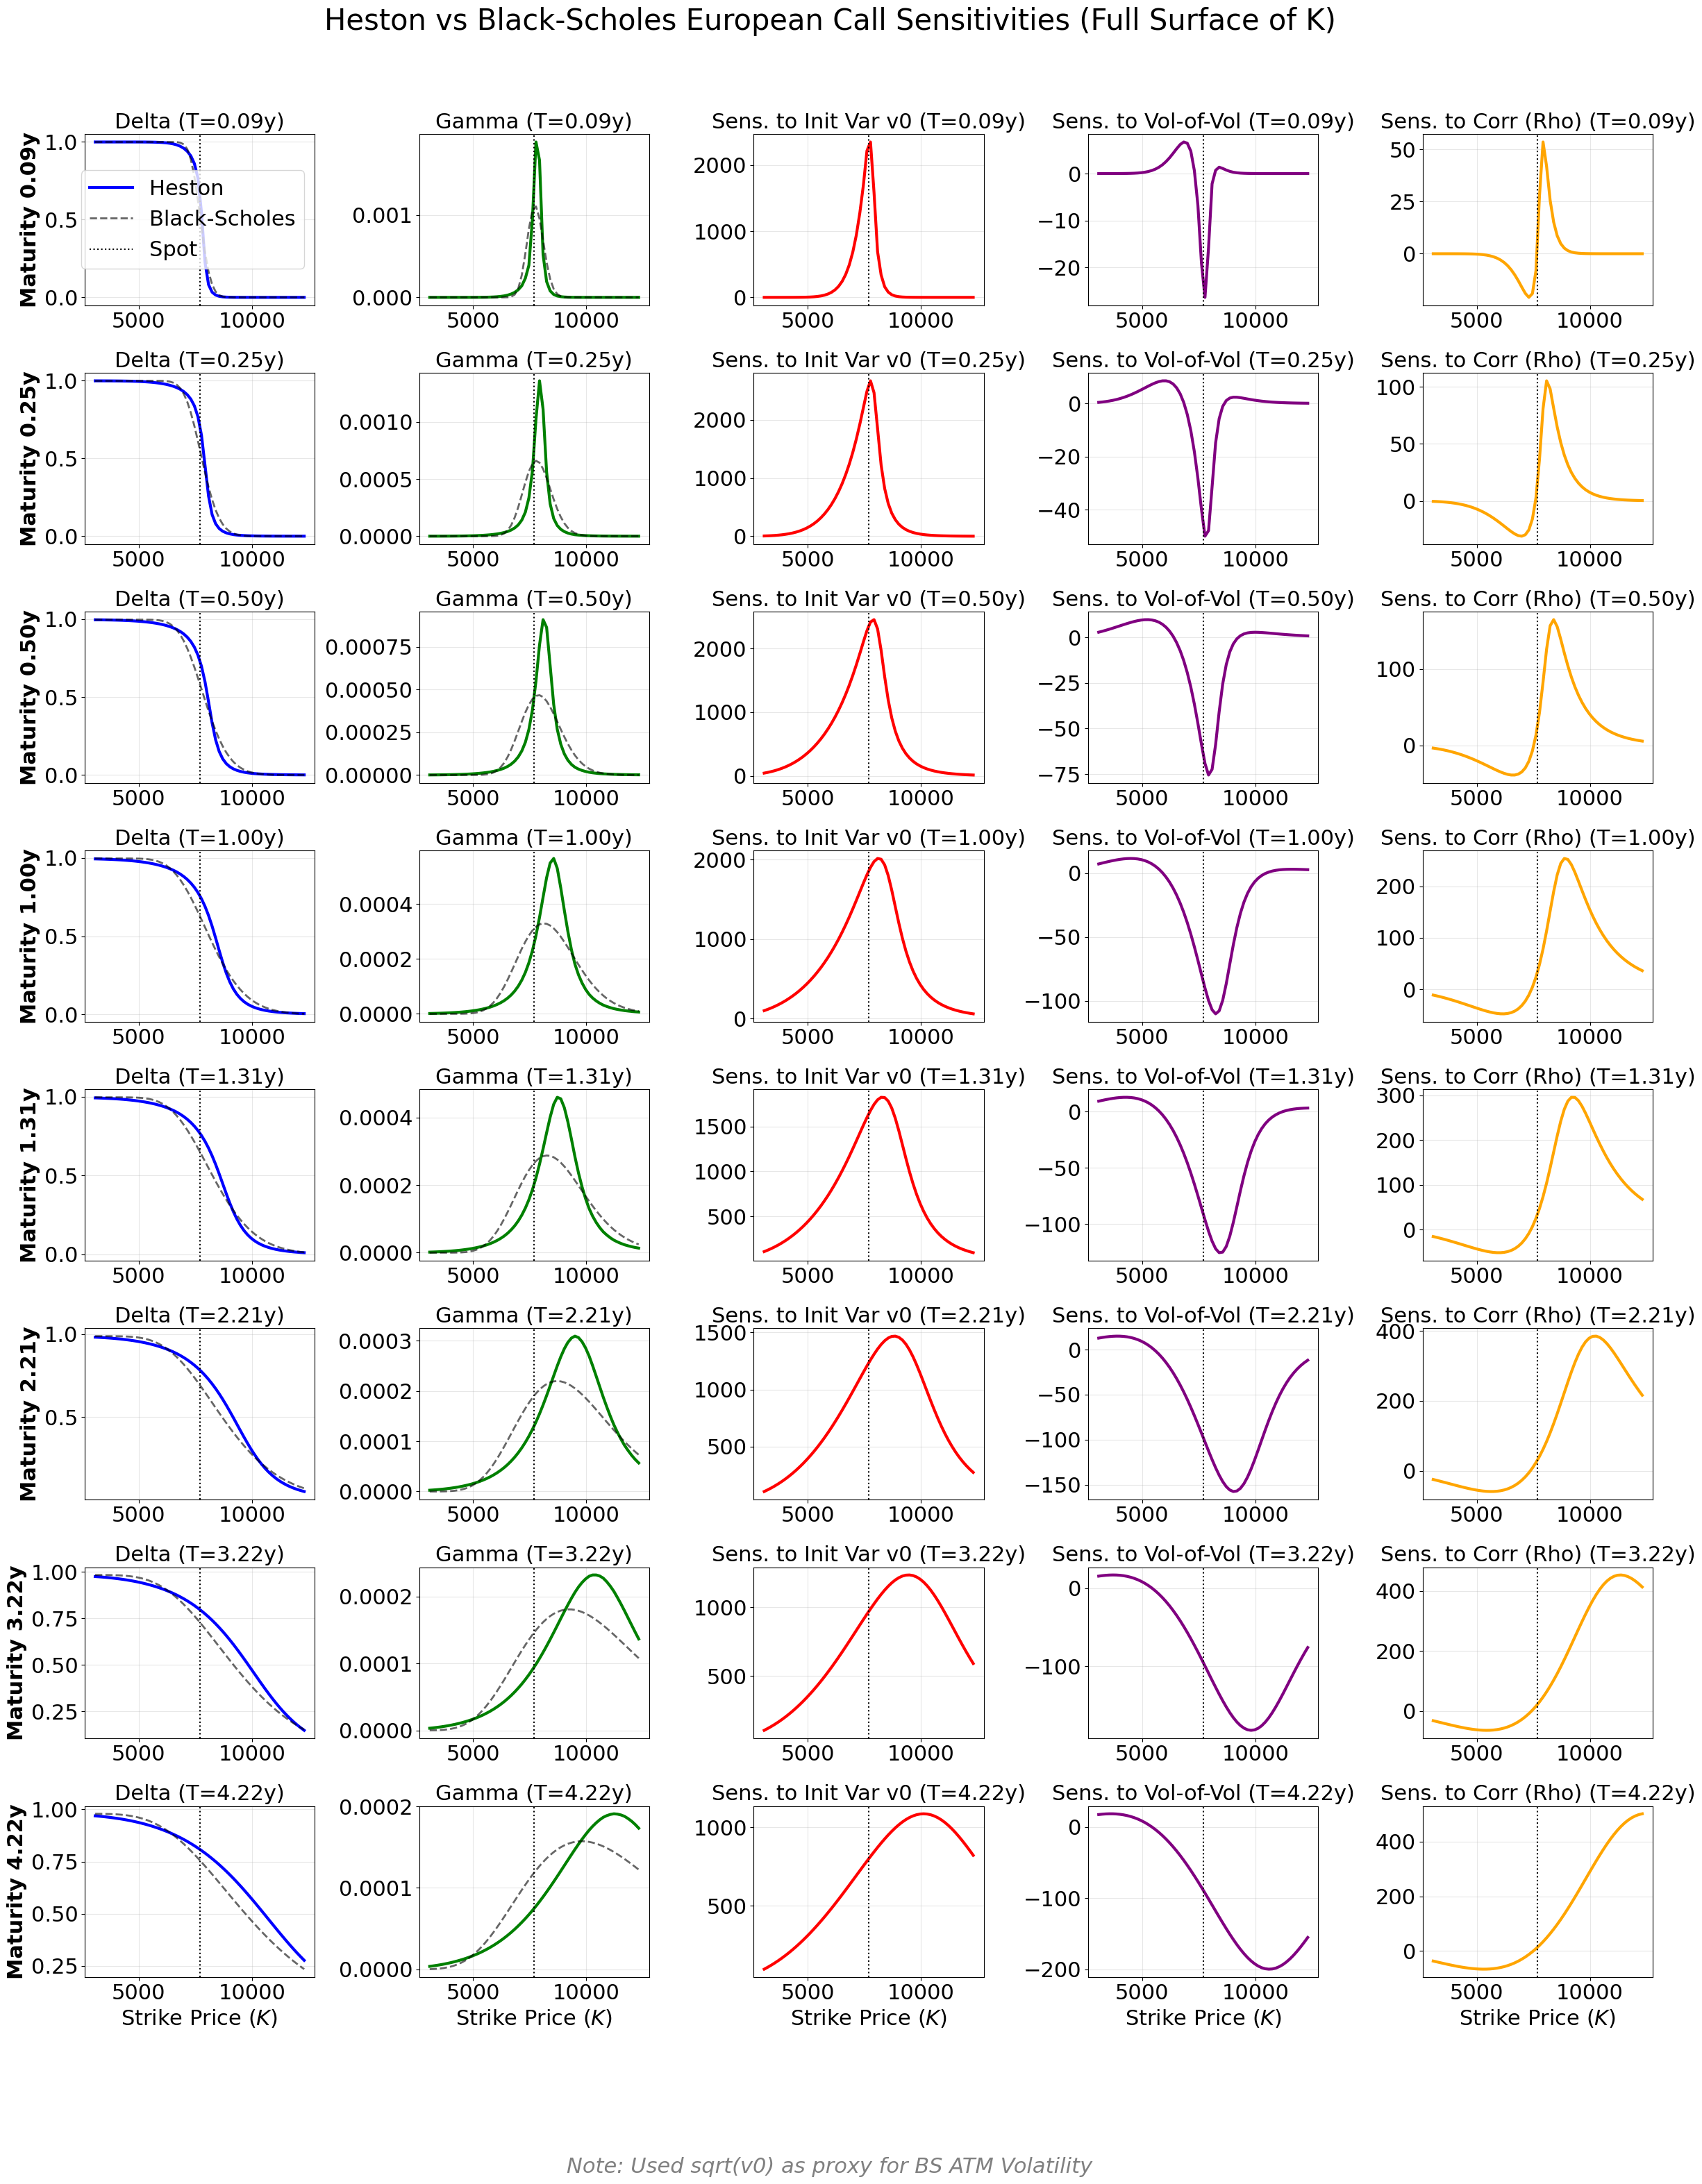

In [28]:
def calculate_bs_call_greeks(S, K, T, r, q, sigma):
    """
    Analytic Black-Scholes Delta and Gamma for Call Options.

    Args:
    S: Current stock price
    K: Strike price
    T: Maturity
    r: Riskfree rate
    q: Dividend rate
    sigma: Volatility

    Returns:
    delta, gamma
    """
    # Prevent division by zero for very short maturities
    T = np.maximum(T, 1e-5)

    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    nd1 = norm.pdf(d1)
    Nd1 = norm.cdf(d1)

    delta = np.exp(-q * T) * Nd1
    gamma = (np.exp(-q * T) * nd1) / (S * sigma * np.sqrt(T))

    return delta, gamma

def calculate_heston_call_greeks(calibrator, params):
    """
    Calculates Heston Delta, Gamma, Vega (v0), and Volga (sigma) for ALL market options
    using the FFT engine (vectorized).

    Args:
    calibrator: HestonCalibration object
    params: Optimized Heston parameters

    Returns:
    delta, gamma, sensitivity to initial variance v0 (vega), sensitivity to vol-and-vol rho (volga)
    """
    calib = copy.deepcopy(calibrator)
    # Use small epsilon for FFT to capture sharp peaks
    eps_spot = calibrator.S0 * 0.001
    eps_vol  = 1e-4

    # Delta, Gamma
    S0_orig = calib.S0

    calib.S0 = S0_orig + eps_spot
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_up = calib.price_surface(params)

    calib.S0 = S0_orig - eps_spot
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_dn = calib.price_surface(params)

    calib.S0 = S0_orig
    for b in calib.data_batches:
        b['k_market'] = np.log(calib.S0 / b['strikes'])
    C_mid = calib.price_surface(params)

    delta = (C_up - C_dn) / (2 * eps_spot)
    gamma = (C_up - 2 * C_mid + C_dn) / (eps_spot**2)

    # Vega, Volga
    kappa, theta, sigma, rho, v0 = params

    params_v_up = [kappa, theta, sigma, rho, v0 + eps_vol]
    params_v_dn = [kappa, theta, sigma, rho, v0 - eps_vol]
    C_v_up = calib.price_surface(params_v_up)
    C_v_dn = calib.price_surface(params_v_dn)
    vega_v0 = (C_v_up - C_v_dn) / (2 * eps_vol)

    params_s_up = [kappa, theta, sigma + eps_vol, rho, v0]
    params_s_dn = [kappa, theta, sigma - eps_vol, rho, v0]
    C_s_up = calib.price_surface(params_s_up)
    C_s_dn = calib.price_surface(params_s_dn)
    sens_sigma = (C_s_up - C_s_dn) / (2 * eps_vol)

    # Sens to Correlation (Heston Rho)
    params_r_up = [kappa, theta, sigma, rho + eps_vol, v0]
    params_r_dn = [kappa, theta, sigma, rho - eps_vol, v0]
    C_r_up = calib.price_surface(params_r_up)
    C_r_dn = calib.price_surface(params_r_dn)
    sens_rho = (C_r_up - C_r_dn) / (2 * eps_vol)

    return delta, gamma, vega_v0, sens_sigma, sens_rho


def plot_greeks_profile(calibrator, params):
    """
    Plots Greeks vs Strike.
    Overlays BS for Delta/Gamma. Plots Heston-specific sensitivities for others.
    """

    plot_calib = copy.deepcopy(calibrator)
    S0 = plot_calib.S0
    wide_strikes = np.linspace(S0 * 0.4, S0 * 1.6, 60)

    for batch in plot_calib.data_batches:
        batch['strikes'] = wide_strikes
        batch['k_market'] = np.log(S0 / wide_strikes)

    delta, gamma, vega, volga, sens_rho = calculate_heston_call_greeks(plot_calib, params)

    unique_Ts = [b['T'] for b in plot_calib.data_batches]
    n_rows = len(unique_Ts)
    fig, axes = plt.subplots(n_rows, 5, figsize=(24, 4 * n_rows))

    FS_SUP   = 30
    FS_TITLE = 22
    FS_LABEL = 22
    FS_TICK  = 22

    current_idx = 0
    # Use sqrt(v0) as proxy for BS ATM Volatility
    bs_vol_proxy = np.sqrt(params[4])

    for i, T in enumerate(unique_Ts):
        strikes = wide_strikes
        n_points = len(strikes)

        # Get Rates/Divs for BS
        r_t = calibrator.r_curve(T)
        q_t = plot_calib.data_batches[i]['q']

        # Calculate BS Greeks (Delta/Gamma only)
        bs_d, bs_g = calculate_bs_call_greeks(
            S0, strikes, T, r_t, q_t, bs_vol_proxy
        )

        # Slices
        d_sub = delta[current_idx : current_idx + n_points]
        g_sub = gamma[current_idx : current_idx + n_points]
        v_sub = vega[current_idx : current_idx + n_points]
        s_sub = volga[current_idx : current_idx + n_points]
        rho_sub = sens_rho[current_idx : current_idx + n_points]
        current_idx += n_points

        # Helper
        def style_ax(ax, title):
            ax.set_title(title, fontsize=FS_TITLE)
            ax.tick_params(axis='both', which='major', labelsize=FS_TICK)
            ax.grid(True, alpha=0.3)
            ax.yaxis.get_offset_text().set_fontsize(FS_TICK)
            ax.axvline(S0, color='k', linestyle=':', alpha=1, label='Spot')

        # Column 0: Delta (overlay BS)
        ax = axes[i, 0] if n_rows > 1 else axes[0]
        ax.plot(strikes, d_sub, 'b-', lw=3, label='Heston')
        ax.plot(strikes, bs_d, 'k--', lw=2, alpha=0.6, label='Black-Scholes')
        style_ax(ax, f"Delta (T={T:.2f}y)")
        ax.set_ylabel(f"Maturity {T:.2f}y", fontsize=FS_LABEL, fontweight='bold')
        if i == 0:
            ax.legend(fontsize=22)

        # Column 1: Gamma (overlay BS)
        ax = axes[i, 1] if n_rows > 1 else axes[1]
        ax.plot(strikes, g_sub, 'g-', lw=3)
        ax.plot(strikes, bs_g, 'k--', lw=2, alpha=0.6)
        style_ax(ax, f"Gamma (T={T:.2f}y)")

        # Column 2: Vega (Heston only)
        ax = axes[i, 2] if n_rows > 1 else axes[2]
        ax.plot(strikes, v_sub, 'r-', lw=3)
        style_ax(ax, f"Sens. to Init Var v0 (T={T:.2f}y)")

        # Column 3: Volga (Heston only)
        ax = axes[i, 3] if n_rows > 1 else axes[3]
        ax.plot(strikes, s_sub, 'purple', lw=3)
        style_ax(ax, f"Sens. to Vol-of-Vol (T={T:.2f}y)")

        # Column 4: Sens to Correlation (Rho, Heston only)
        ax = axes[i, 4] if n_rows > 1 else axes[4]
        ax.plot(strikes, rho_sub, 'orange', lw=3)
        style_ax(ax, f"Sens. to Corr (Rho) (T={T:.2f}y)")

        if i == n_rows - 1:
            for j in range(5):
                axes[i, j].set_xlabel("Strike Price ($K$)", fontsize=FS_LABEL)

    plt.suptitle("Heston vs Black-Scholes European Call Sensitivities (Full Surface of K)", fontsize=FS_SUP, y=0.995)
    fig.text(0.5, 0.02, "Note: Used sqrt(v0) as proxy for BS ATM Volatility",
             ha='center', fontsize=22, style='italic', color='gray')

    plt.tight_layout(rect=[0, 0.08, 1, 0.97], h_pad=2.0)
    plt.show()

plot_greeks_profile(calibrator_full, result.x)

## 4. Risk Analysis & Interpretation


### Component Greeks (principal + coupons - DI put)
Simulations were performed using 10,000 paths across 60 spot price levels. To optimize performance, the pricing engine was modified to generate "unit paths" ($S_0=1$), allowing specific path sets to be recycled across all spot levels for each sensitivity. An optional time_to_maturity parameter was also implemented to visualize sharp sensitivity changes at shorter maturities.

The note displays clear regime near barriers for coupon and put components, while in the middle for the principal component.

Simulating T=4.01y (Pricing Date: 2026-09-30)
Pre-computing paths...


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 41.9%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 41.9%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 42.0%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 42.0%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 41.8%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 41.9%.


Simulation complete (qe): 10000 paths over 4.01 years (1017 steps), zero-variance share 41.9%.
Scanning 60 spot levels...


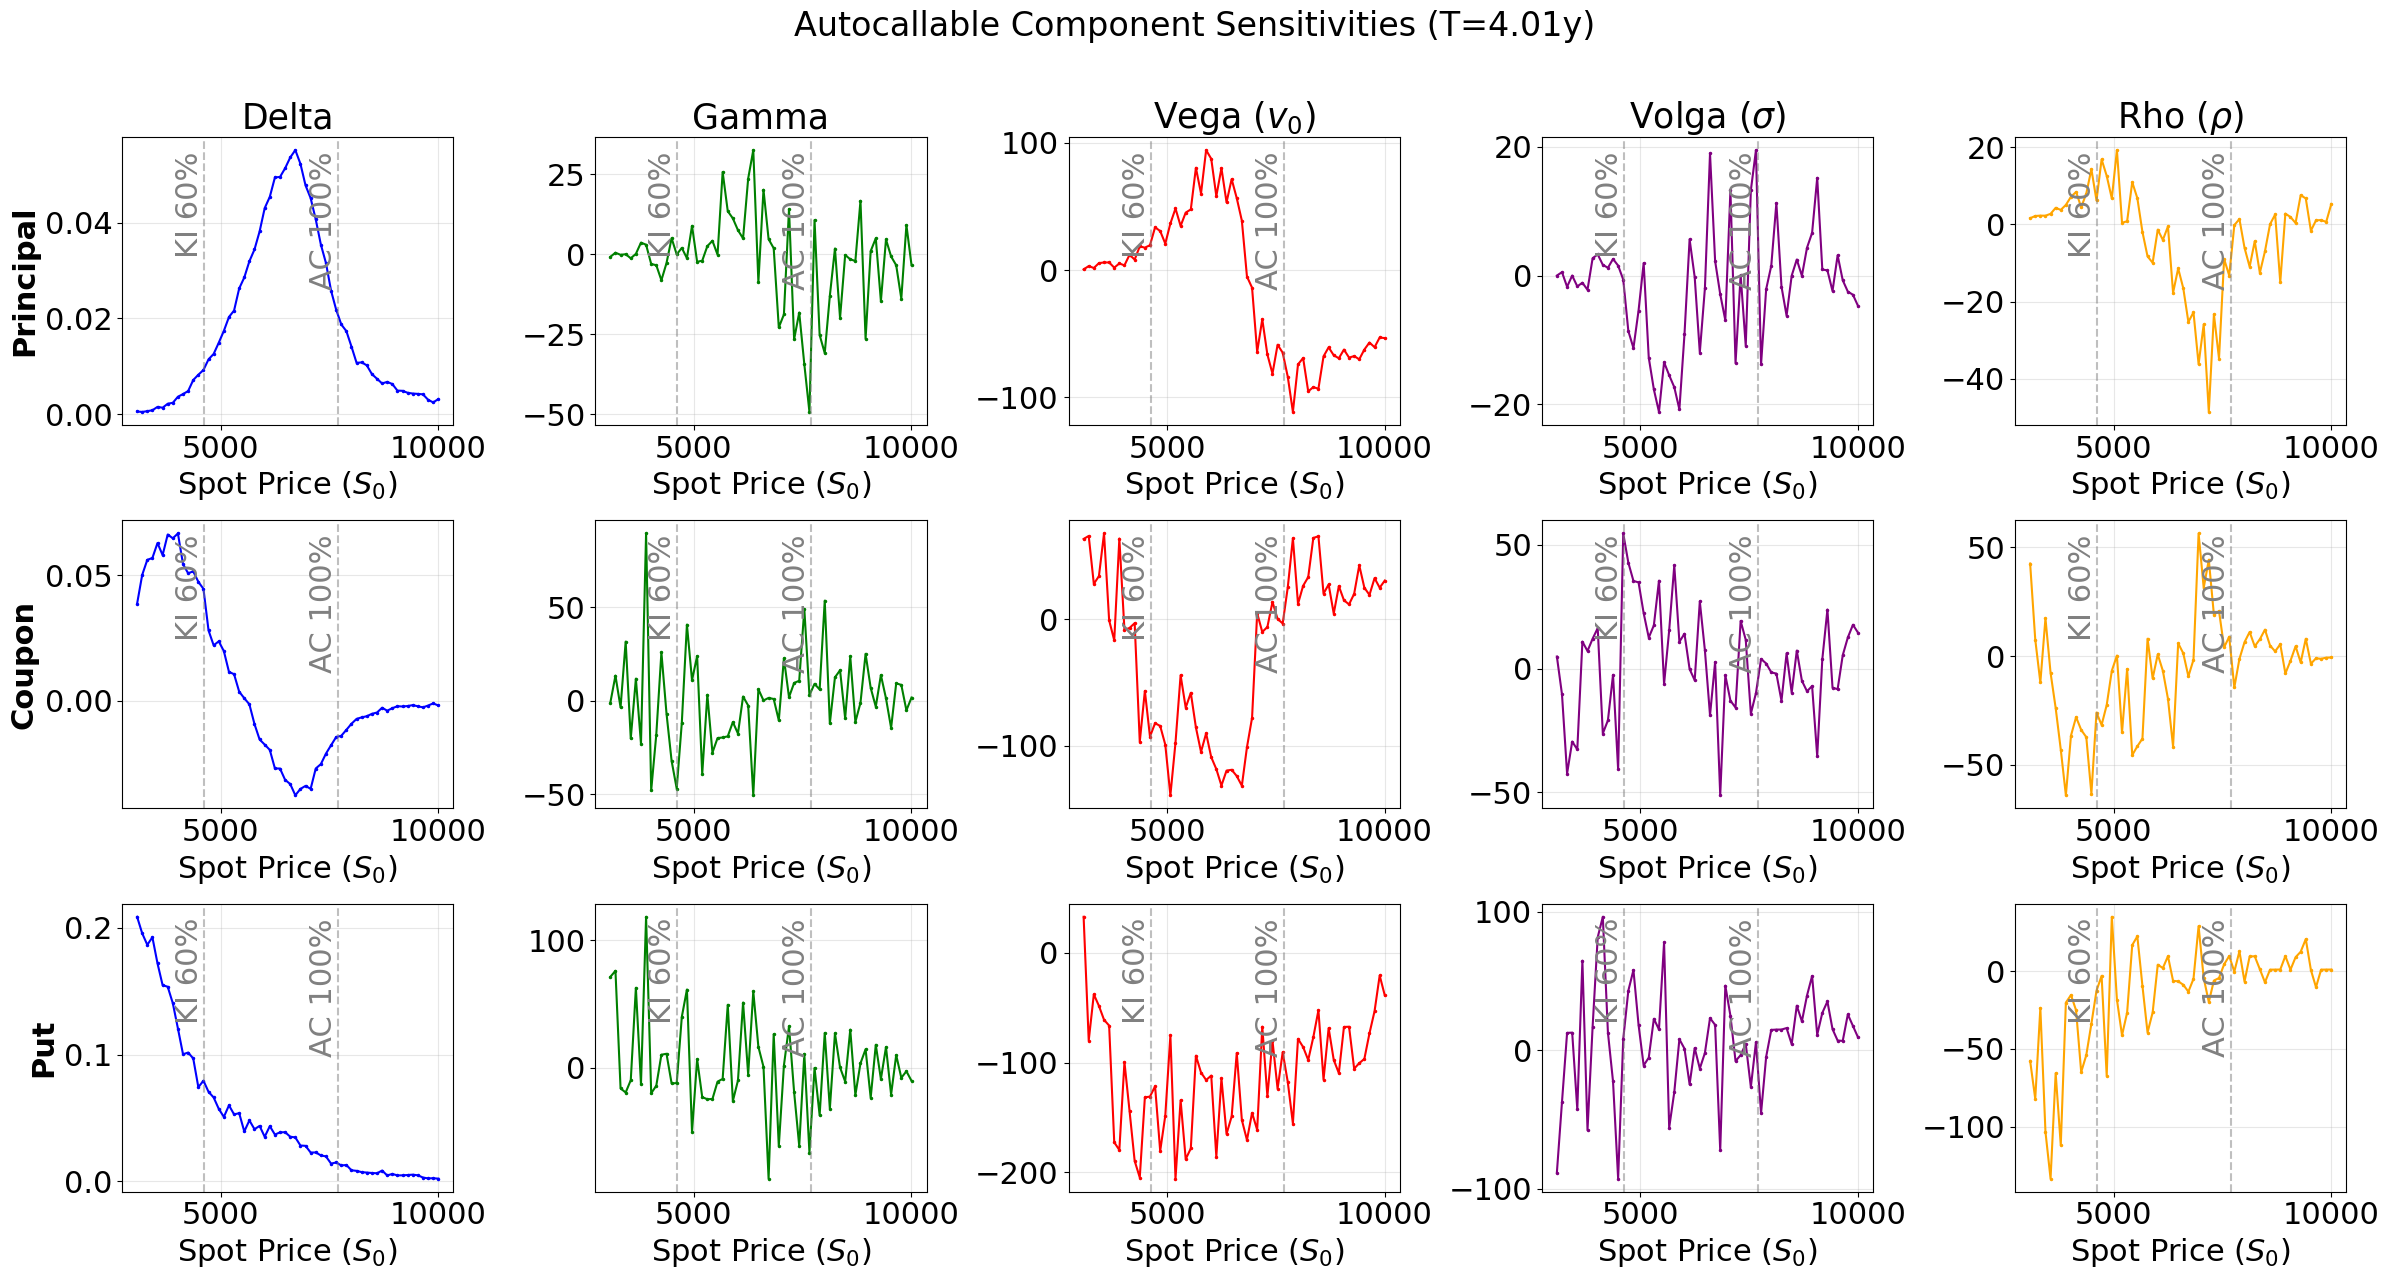

Simulating T=0.4932y (Pricing Date: 2030-04-06)
Pre-computing paths...
Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.6%.


Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.2%.
Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 41.0%.


Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.7%.
Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.5%.


Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.6%.
Simulation complete (qe): 10000 paths over 0.49 years (125 steps), zero-variance share 40.6%.
Scanning 60 spot levels...


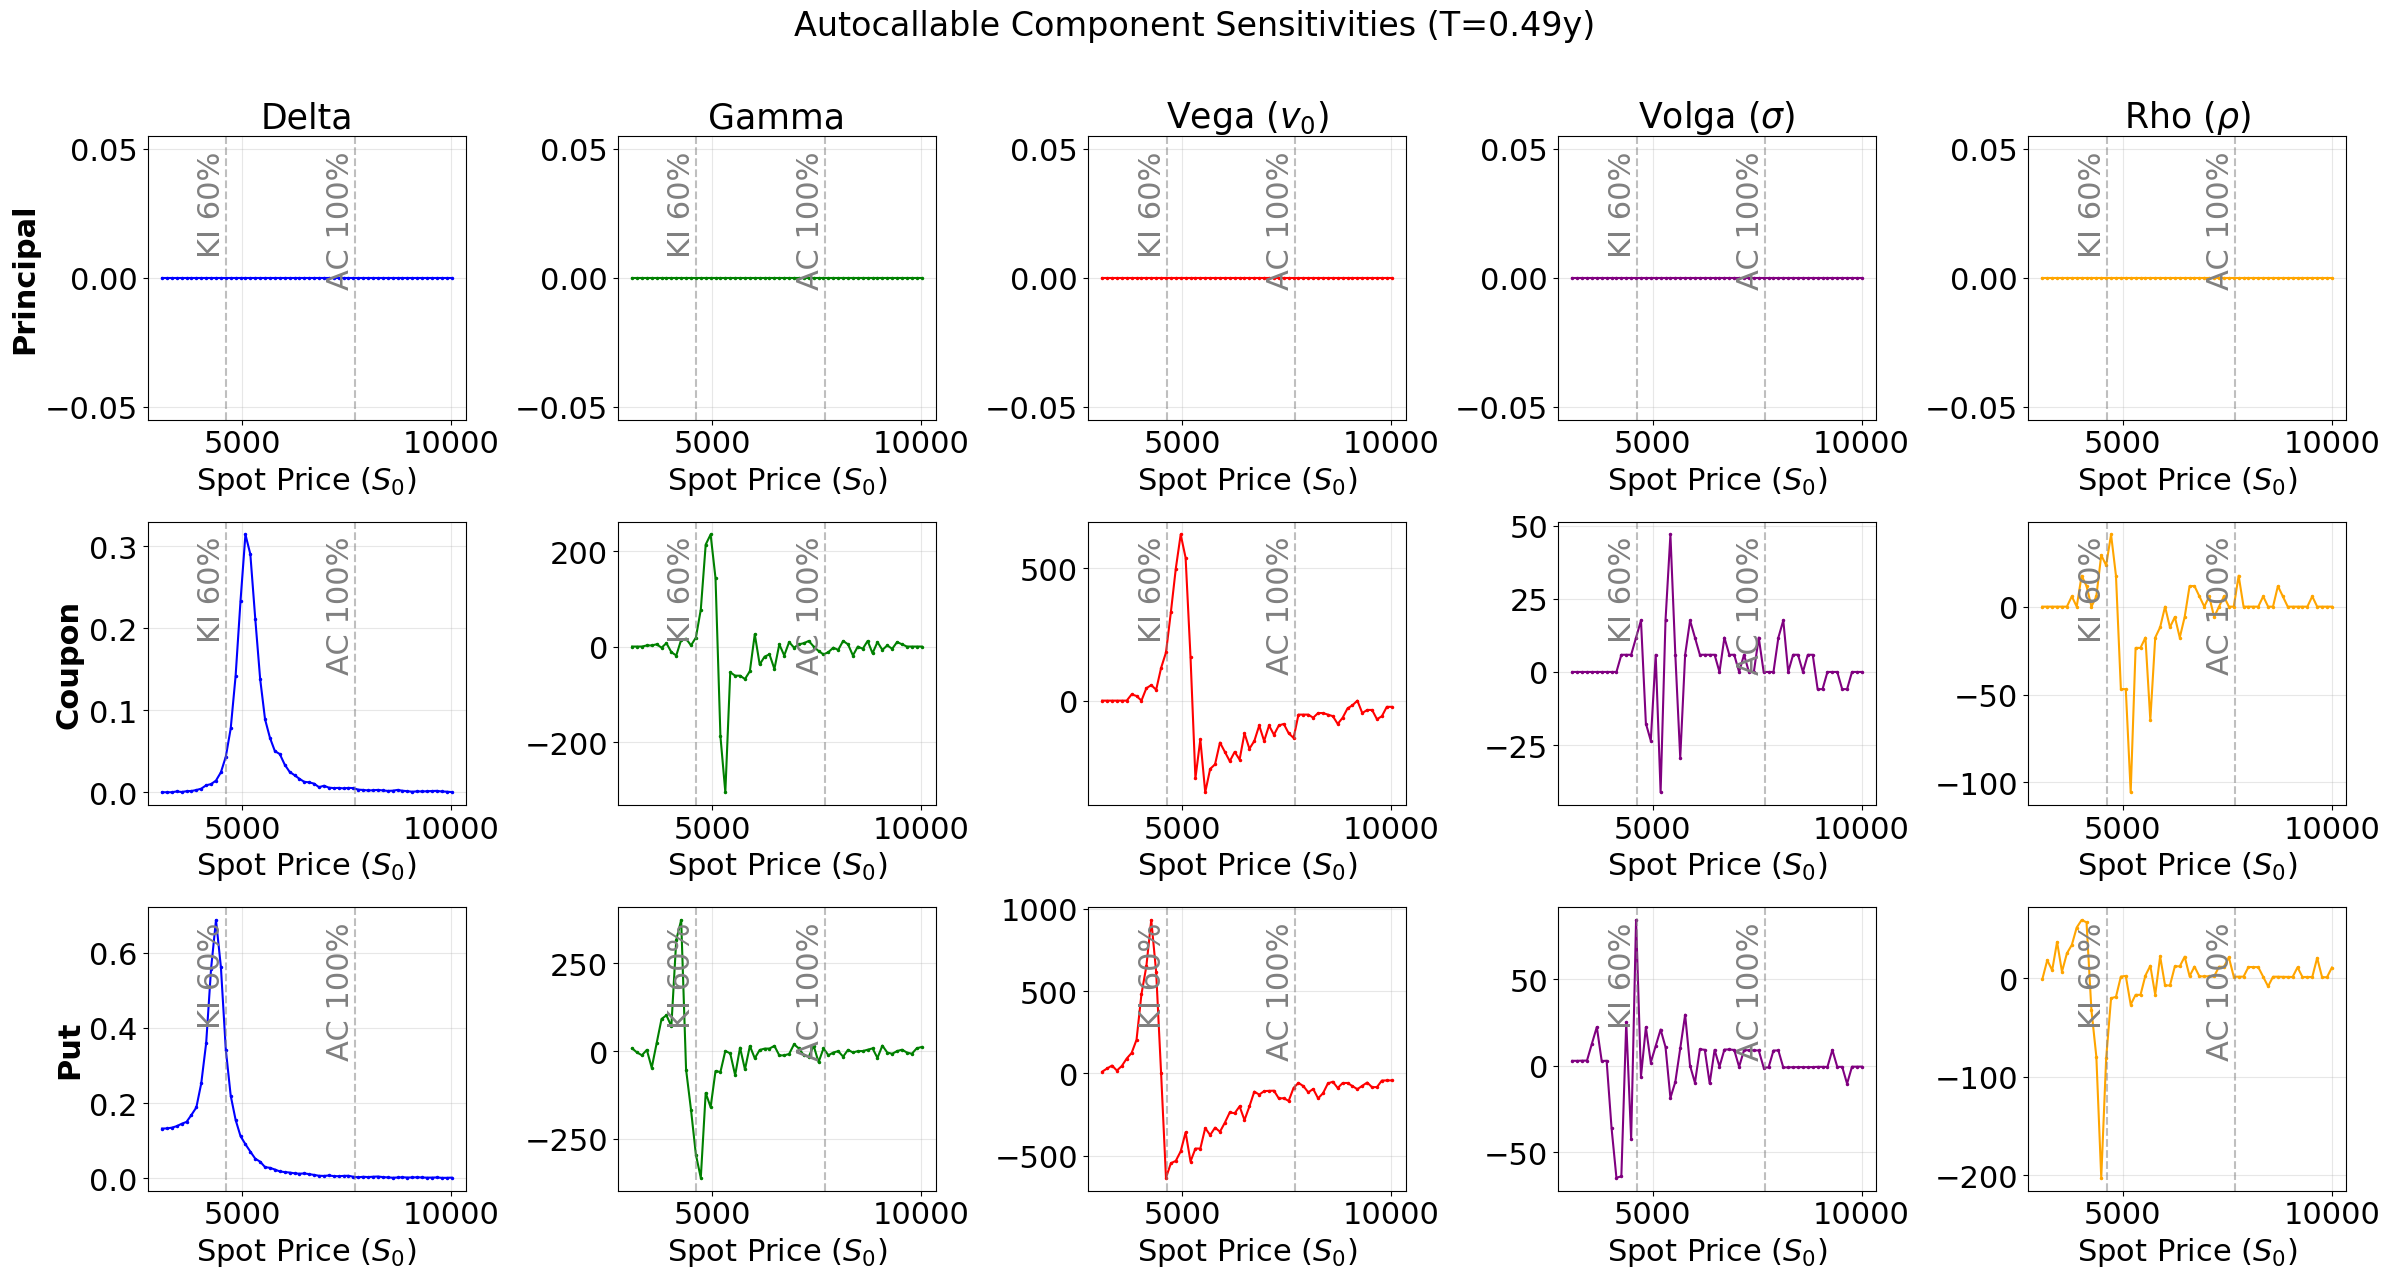

Simulating T=0.0822y (Pricing Date: 2030-09-03)
Pre-computing paths...
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 29.0%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 27.9%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 30.2%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 29.1%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 28.9%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 29.0%.
Simulation complete (qe): 10000 paths over 0.08 years (21 steps), zero-variance share 29.0%.
Scanning 60 spot levels...


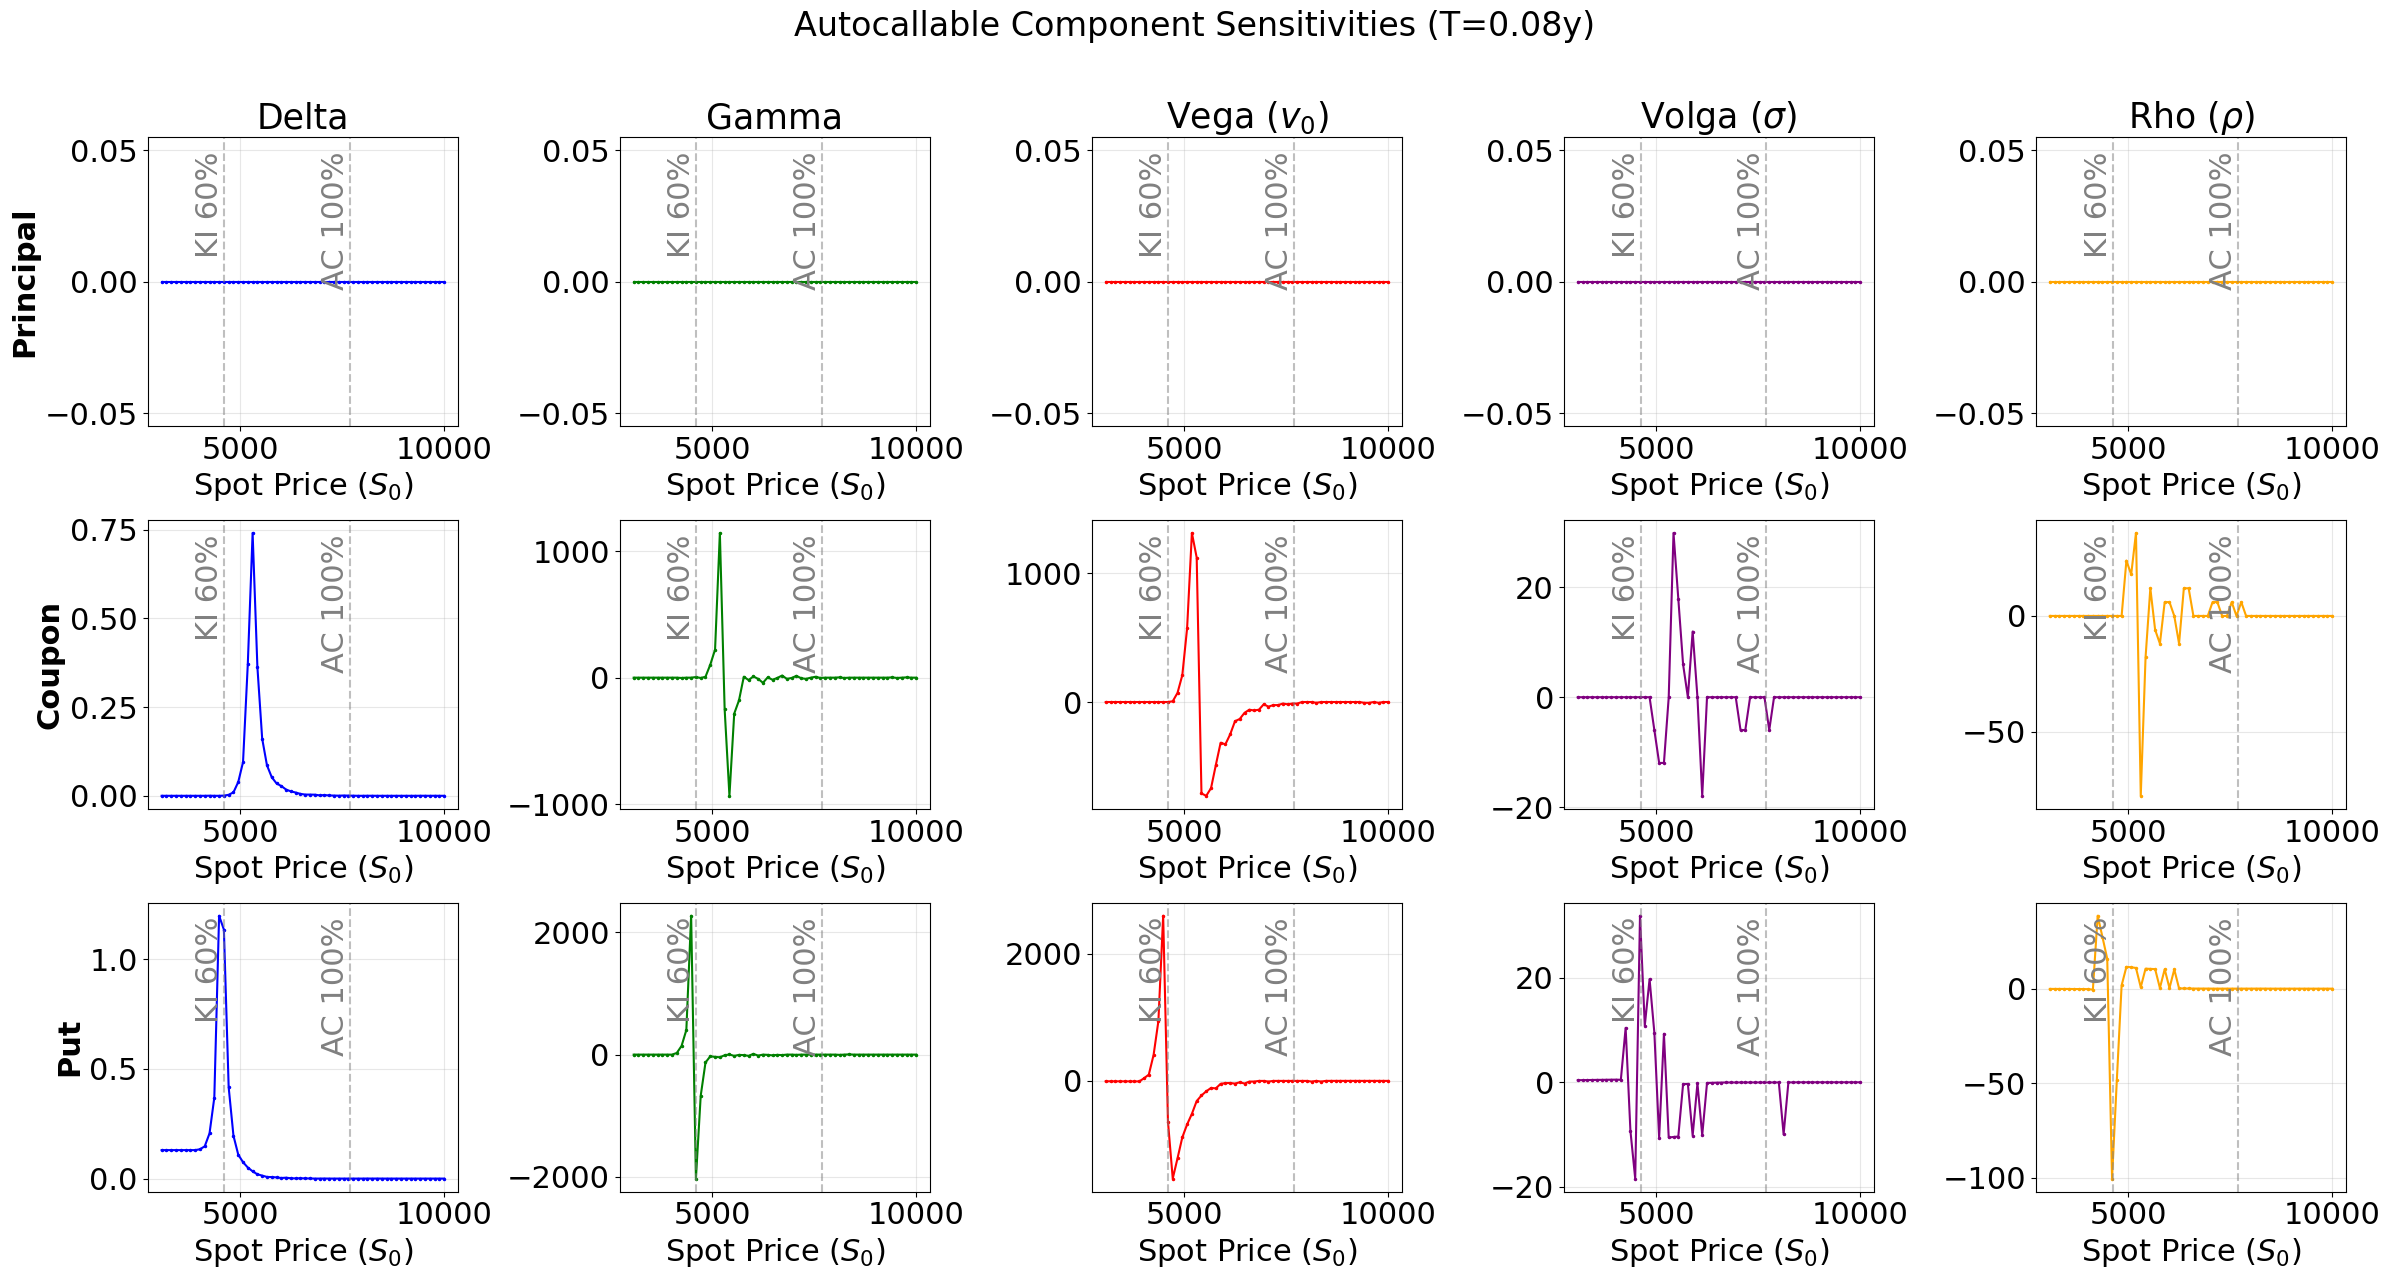

In [29]:
def plot_component_greeks(base_pricer, product_params, time_to_maturity=None):
    s_ref = base_pricer.S_ref
    spots = np.linspace(s_ref * 0.4, s_ref * 1.3, 60)


    last_date_str = product_params['full_schedule'][-1]
    maturity_date = datetime.strptime(last_date_str, "%Y-%m-%d")
    today = PRICING_DATE
    full_horizon_years = (maturity_date - today).days / 365

    # Deterine time to maturity and pricing date
    if time_to_maturity is not None:
        # Force T to specific value
        T_sim = time_to_maturity

        # Calculate the theoretical future pricing date
        mat_date_str = product_params['full_schedule'][-1]
        mat_date = datetime.strptime(mat_date_str, "%Y-%m-%d")
        sim_date = mat_date - timedelta(days=int(T_sim * 365))

        print(f"Simulating T={T_sim:.4f}y (Pricing Date: {sim_date.date()})")
    else:
        # Standard mode: use pricer's grid or default to 4y
        T_sim = max(full_horizon_years, 0.01)
        sim_date = PRICING_DATE
        print(f"Simulating T={T_sim:.2f}y (Pricing Date: {sim_date.date()})")

    print("Pre-computing paths...")
    # Observation times relative to the (possibly future) pricing date, inserted exactly into the Greek-path grid
    obs_times_sim = HestonAutocallPricer.schedule_to_times(product_params['full_schedule'], sim_date)
    greek_paths = base_pricer.generate_greek_paths(T_max=T_sim, n_paths=10000, obs_times=obs_times_sim)

    print(f"Scanning {len(spots)} spot levels...")
    history = {'Principal': [], 'Coupon': [], 'Put': []}

    for s in spots:
        temp_p = copy.copy(base_pricer)
        temp_p.S0 = s

        # Explicitly pass the pre-computed data
        with suppress_stdout():
            greeks = temp_p.compute_sensitivities(product_params, path_set=greek_paths, pricing_date=sim_date)

        for c in ['Principal', 'Coupon', 'Put']:
            history[c].append(greeks[c])

    # Plot
    fig, axes = plt.subplots(3, 5, figsize=(24, 13))
    components = ['Principal', 'Coupon', 'Put']
    greeks = ['Delta', 'Gamma', 'Vega', 'Volga', 'Rho']
    colors = ['blue', 'green', 'red', 'purple', 'orange']

    for i, comp in enumerate(components):
        data_list = history[comp]

        for j, greek in enumerate(greeks):
            ax = axes[i, j]
            y_vals = [d[greek] for d in data_list]
            ax.plot(spots, y_vals, '.-', color=colors[j], lw=1.5, markersize=3)
            ax.tick_params(axis='both',which='major', labelsize=22)

            if i == 0:
                title_map = {
                    'Vega': r'Vega ($v_0$)',
                    'Volga': r'Volga ($\sigma$)',
                    'Rho': r'Rho ($\rho$)'
                }
                ax.set_title(title_map.get(greek, greek), fontsize=25)

            if j == 0:
                ax.set_ylabel(comp, fontsize=22, fontweight='bold')

            ax.grid(True, alpha=0.3)

            # Barriers text
            ki_level = s_ref * 0.60
            ac_level = s_ref * 1.00

            ax.axvline(ki_level, color='gray', ls='--', alpha=0.5)
            ax.axvline(ac_level, color='gray', ls='--', alpha=0.5)

            trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
            ax.text(ki_level, 0.95, "KI 60%", transform=trans, ha='right', va='top', fontsize=22, color='gray', rotation=90)
            ax.text(ac_level, 0.95, "AC 100%", transform=trans, ha='right', va='top', fontsize=22, color='gray', rotation=90)
            ax.set_xlabel("Spot Price ($S_0$)", fontsize=22)

    if time_to_maturity:
        title = f" (T={T_sim:.2f}y)"
    else:
        title = f" (T={T_sim:.2f}y)"
    plt.suptitle("Autocallable Component Sensitivities"+title, fontsize=24, y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Run it
plot_component_greeks(pricer, PRODUCT_PARAMS)
plot_component_greeks(pricer, PRODUCT_PARAMS, time_to_maturity = 180/365)
plot_component_greeks(pricer, PRODUCT_PARAMS, time_to_maturity = 30/365)


Scanning Rho sensitivity...


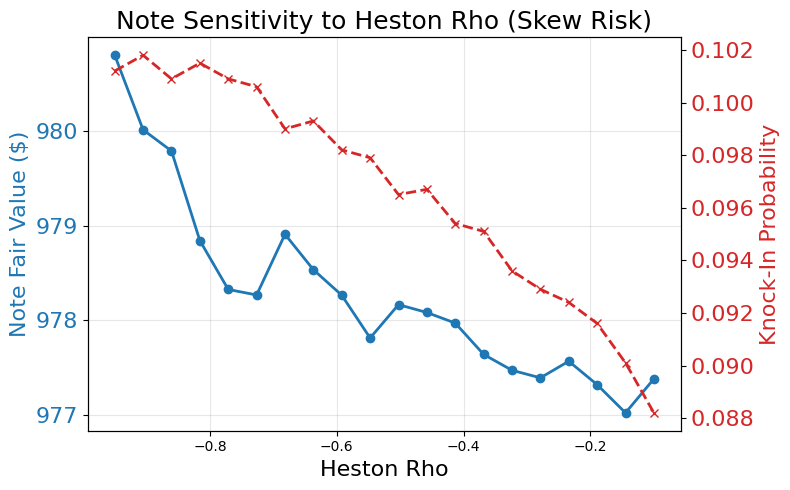

In [30]:
def analyze_product_sensitivities(pricer, product_params, current_params, seed=42):
    """
    Analyzes sensitivity to Rho in Heston model.
    """
    kappa, theta, sigma, rho_orig, v0 = current_params

    # Range of correlations: Heston usually has negative rho (-0.9 to -0.3)
    rho_values = np.linspace(-0.95, -0.1, 20)

    prices = []
    ki_probs = []

    # Barrier Level
    B_knock_in = product_params['barrier_knock_in'] * pricer.S_ref

    print(f"Scanning Rho sensitivity...")

    for rho in rho_values:
        # Update parameters
        new_params = [kappa, theta, sigma, rho, v0]

        # Update pricer
        temp_pricer = HestonAutocallPricer(
            pricer.S0,
            pricer.S_ref,
            pricer.r_curve_func,
            pricer.q_curve_func,
            new_params
        )

        # Determine T_max based on schedule
        last_date = datetime.strptime(product_params['full_schedule'][-1], "%Y-%m-%d")
        current_date = PRICING_DATE

        T_max = (last_date - current_date).days / 365.0

        np.random.seed(seed)
        temp_pricer.run_simulation(T_max=T_max, steps_per_year=252, n_paths=10000, obs_times=OBS_TIMES, verbose=False)

        price_tuple = temp_pricer.price_structure(**product_params, pricing_date=PRICING_DATE, verbose=False)
        prices.append(price_tuple[0])

        # Calculate Knock-In Probability
        S_final = temp_pricer.S_paths[-1, :]
        prob = np.mean(S_final < B_knock_in)
        ki_probs.append(prob)

    fig, ax1 = plt.subplots(figsize=(8, 5))

    color = 'tab:blue'
    ax1.set_xlabel('Heston Rho', fontsize=16)
    ax1.set_ylabel('Note Fair Value ($)', color=color, fontsize=16)
    ax1.plot(rho_values, prices, 'o-', color=color, lw=2, label='Note Price')
    ax1.tick_params(axis='y', labelcolor=color, labelsize=16)
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Knock-In Probability', color=color, fontsize=16)
    ax2.plot(rho_values, ki_probs, 'x--', color=color, lw=2, label='KI Prob')
    ax2.tick_params(axis='y', labelcolor=color, labelsize=16)

    plt.title("Note Sensitivity to Heston Rho (Skew Risk)", fontsize=18)
    fig.tight_layout()
    plt.show()

analyze_product_sensitivities(pricer, PRODUCT_PARAMS, result.x)

Calculating Price Profile (PV vs Spot)...


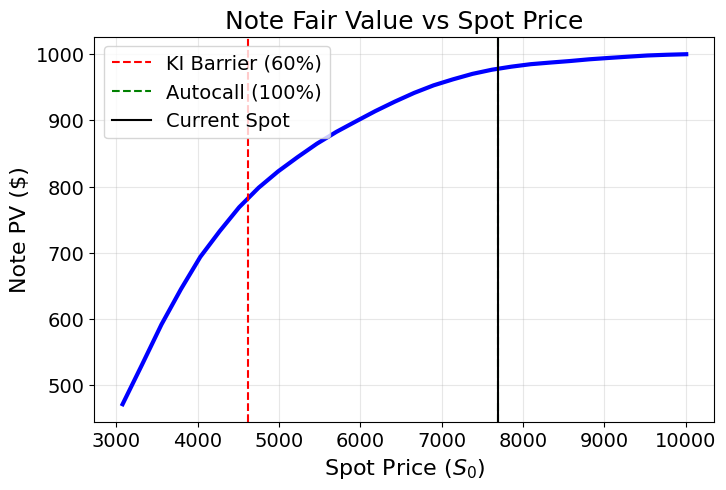

In [31]:
def plot_price_profile(base_pricer, product_params):
    """
    Calculates the Total Note Price vs Spot (The "Payoff Profile").
    """
    S_ref = base_pricer.S_ref

    spot_levels = np.linspace(0.4 * S_ref, 1.3 * S_ref, 30)
    note_prices = []

    print("Calculating Price Profile (PV vs Spot)...")

    # Determine T_max based on schedule in params
    last_date = datetime.strptime(product_params['full_schedule'][-1], "%Y-%m-%d")
    now_date = PRICING_DATE

    T_max = (last_date - now_date).days / 365

    for S in spot_levels:
        temp_pricer = HestonAutocallPricer(
            S,
            S_ref,
            base_pricer.r_curve_func,
            base_pricer.q_curve_func,
            [base_pricer.kappa, base_pricer.theta, base_pricer.sigma, base_pricer.rho, base_pricer.v0]
        )

        np.random.seed(MC_SEED)   # common random numbers across spot levels
        temp_pricer.run_simulation(T_max, steps_per_year=252, n_paths=10000, obs_times=OBS_TIMES, verbose=False)

        price_tuple = temp_pricer.price_structure(**product_params, pricing_date=PRICING_DATE, verbose=False)
        note_prices.append(price_tuple[0])

    plt.figure(figsize=(8, 5))
    plt.plot(spot_levels, note_prices, 'b-', lw=3)

    plt.axvline(0.60 * S_ref, color='r', linestyle='--', label='KI Barrier (60%)')
    plt.axvline(1.00 * S_ref, color='g', linestyle='--', label='Autocall (100%)')

    plt.axvline(base_pricer.S0, color='black', linestyle='-', label='Current Spot')

    plt.title("Note Fair Value vs Spot Price", fontsize=18)
    plt.xlabel("Spot Price ($S_0$)", fontsize=16)
    plt.ylabel("Note PV ($)", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.show()

plot_price_profile(pricer, PRODUCT_PARAMS)

References

Heston (1993): "A Closed-Form Solution for Options with Stochastic Volatility."

Lewis (2001): "A Simple Option Formula for General Jump-Diffusion Models."

Andersen (2008): "Simple and Efficient Simulation of the Heston Stochastic Volatility Model." Journal of Computational Finance 11(3).

Lord, Koekkoek, van Dijk (2010): "A Comparison of Biased Simulation Schemes for Stochastic Volatility Models." Quantitative Finance 10(2).

Code Reference: The FFT calibration implementation was adapted from the Financial Models & Numerical Methods repository by [Cantaro86](https://github.com/cantaro86/Financial-Models-Numerical-Methods).

MC price from the path classification: 975.40  (s.e. 0.70)
Autocalled 87.0% | survived to maturity above KI 8.1% (bonus 6.5%, par 1.6%) | knocked in 4.9%


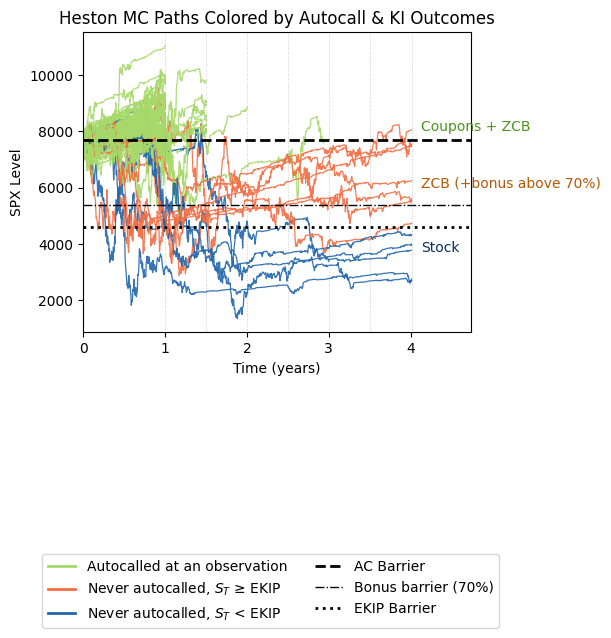

Fair value from price_structure: 975.40; difference: -0.0000


In [32]:

def run_autocall_mc_and_plot(
    pricer,
    PRODUCT_SCHEDULE,
    pricing_date=None,           # datetime or "YYYY-MM-DD"; if None uses PRICING_DATE
    AC_frac=1.0,
    RED_frac=0.7,
    EKIP_frac=0.6,
    notional=1000.0,
    coupon_step=0.03,
    exit_bonus=0.24,
    payment_lag_days=7,
    steps_per_year=252,
    n_paths=50000,
    n_plot=80,
    seed=123,
    out_png="athena_paths_truncated_legend_below.png",
    force_unit_start=False
):
    """
    Monte Carlo payoff classification + truncated-path plot on the pricer's paths.
    v2: the payoff now matches price_structure exactly (autocall at >=, snowball coupon n x coupon_step,
    70% bonus band, stock payoff below the knock-in, payment lag), so the printed price must equal the
    pricer's fair value when the same paths are used.
    """

    # -----------------------------
    # 0) Pricing date
    # -----------------------------
    if pricing_date is None:
        pricing_date = PRICING_DATE
    elif isinstance(pricing_date, str):
        pricing_date = datetime.strptime(pricing_date, "%Y-%m-%d")

    # -----------------------------
    # 1) Build obs_times from schedule
    # -----------------------------
    schedule_dates = [datetime.strptime(d, "%Y-%m-%d") for d in PRODUCT_SCHEDULE]
    future_dates = sorted([d for d in schedule_dates if d > pricing_date])
    if not future_dates:
        raise ValueError("No future observation dates found in PRODUCT_SCHEDULE relative to pricing_date.")

    obs_times = np.array([(d - pricing_date).days / 365.0 for d in future_dates], dtype=float)
    T_maturity = float(obs_times[-1])
    lag = payment_lag_days / 365.0

    # -----------------------------
    # 2) Ensure simulation horizon covers maturity
    # -----------------------------
    need_sim = (getattr(pricer, "S_paths", None) is None) or (getattr(pricer, "time_grid", None) is None)
    if not need_sim and pricer.time_grid[-1] < T_maturity - 1e-6:
        need_sim = True
    if need_sim:
        pricer.run_simulation(T_max=T_maturity, steps_per_year=steps_per_year, n_paths=n_paths,
                              obs_times=obs_times, seed=seed, force_unit_start=force_unit_start)

    S_paths = pricer.S_paths
    time_grid = pricer.time_grid
    n_steps_plus_1, n_paths_actual = S_paths.shape

    # -----------------------------
    # 3) Map obs_times to indices
    # -----------------------------
    obs_idx = [pricer._get_time_index(T) for T in obs_times]
    idx_maturity = obs_idx[-1]

    # -----------------------------
    # 4) Barriers
    # -----------------------------
    AC_barrier = AC_frac * pricer.S_ref
    RED = RED_frac * pricer.S_ref
    EKIP = EKIP_frac * pricer.S_ref

    # -----------------------------
    # 5) Payoff rules & classification (vectorised)
    # -----------------------------
    r_curve_func = pricer.r_curve_func
    payoffs = np.zeros(n_paths_actual)
    regions = np.full(n_paths_actual, 1, dtype=int)   # 0 autocalled, 1 survived above KI, 2 knocked in
    call_index = np.full(n_paths_actual, -1, dtype=int)
    call_time = np.full(n_paths_actual, np.nan)
    active = np.ones(n_paths_actual, dtype=bool)

    for k, (T_obs, idx_obs) in enumerate(zip(obs_times[:-1], obs_idx[:-1])):
        n_period = k + 2                      # first observation is one year in: 2 semesters of coupon
        called = active & (S_paths[idx_obs, :] >= AC_barrier)
        t_pay = T_obs + lag
        df_call = np.exp(-float(r_curve_func(t_pay)) * t_pay)
        payoffs[called] = notional * (1.0 + n_period * coupon_step) * df_call
        regions[called] = 0
        call_index[called] = int(idx_obs)
        call_time[called] = float(T_obs)
        active[called] = False

    ST = S_paths[idx_maturity, :]
    t_pay_T = T_maturity + lag
    df_T = np.exp(-float(r_curve_func(t_pay_T)) * t_pay_T)
    bonus = active & (ST >= RED)
    par   = active & (ST >= EKIP) & (ST < RED)
    ki    = active & (ST < EKIP)
    payoffs[bonus] = notional * (1.0 + exit_bonus) * df_T
    payoffs[par]   = notional * df_T
    payoffs[ki]    = notional * (ST[ki] / pricer.S_ref) * df_T
    regions[ki] = 2

    mc_price = float(payoffs.mean())
    print(f"MC price from the path classification: {mc_price:.2f}  (s.e. {payoffs.std(ddof=1)/np.sqrt(n_paths_actual):.2f})")
    print(f"Autocalled {np.mean(regions==0):.1%} | survived to maturity above KI {np.mean(regions==1):.1%} "
          f"(bonus {np.mean(bonus):.1%}, par {np.mean(par):.1%}) | knocked in {np.mean(regions==2):.1%}")

    # -----------------------------
    # 6) Plot
    # -----------------------------
    rng = np.random.default_rng(seed)
    sample_idx = rng.choice(n_paths_actual, size=min(n_plot, n_paths_actual), replace=False)

    color_map = {
        0: "#a6d96a",  # light green (autocalled)
        1: "#f46d43",  # orange (survived, above KI)
        2: "#2166ac",  # dark blue (knock-in region)
    }

    fig, ax = plt.subplots(figsize=(5, 5))

    for idx in sample_idx:
        region = regions[idx]
        col = color_map[region]

        if region == 0 and call_index[idx] >= 0:
            ci = call_index[idx]
            ax.plot(time_grid[:ci+1], S_paths[:ci+1, idx], lw=0.9, alpha=0.9, color=col)
        else:
            ax.plot(time_grid, S_paths[:, idx], lw=0.9, alpha=0.9, color=col)

    ax.axhline(AC_barrier, color="black", linestyle="--", lw=2)
    ax.axhline(RED,        color="black", linestyle="-.", lw=1)
    ax.axhline(EKIP,       color="black", linestyle=":",  lw=2)

    for T_obs in obs_times:
        ax.axvline(T_obs, color="grey", linestyle=":", lw=0.7, alpha=0.4)

    ax.set_xlabel("Time (years)")
    ax.set_ylabel("SPX Level")
    ax.set_title("Heston MC Paths Colored by Autocall & KI Outcomes")

    x_min, x_max = float(time_grid[0]), float(time_grid[-1])
    ax.set_xlim(x_min, x_max * 1.18)

    y_autocall = AC_barrier + 0.15 * (AC_barrier - EKIP)
    y_mid      = 0.5 * (AC_barrier + EKIP)
    y_ki       = EKIP - 0.25 * (AC_barrier - EKIP)
    x_text     = x_max * 1.03

    ax.text(x_text, y_autocall, "Coupons + ZCB", color="#4d9221", fontsize=10, va="center", ha="left")
    ax.text(x_text, y_mid,      "ZCB (+bonus above 70%)", color="#b35806", fontsize=10, va="center", ha="left")
    ax.text(x_text, y_ki,       "Stock",  color="#053061", fontsize=10, va="center", ha="left")

    legend_lines = [
        Line2D([0], [0], color=color_map[0], lw=2, label="Autocalled at an observation"),
        Line2D([0], [0], color=color_map[1], lw=2, label="Never autocalled, $S_T$ \u2265 EKIP"),
        Line2D([0], [0], color=color_map[2], lw=2, label="Never autocalled, $S_T$ < EKIP"),
        Line2D([0], [0], color="black", lw=2, linestyle="--", label="AC Barrier"),
        Line2D([0], [0], color="black", lw=1, linestyle="-.", label="Bonus barrier (70%)"),
        Line2D([0], [0], color="black", lw=2, linestyle=":",  label="EKIP Barrier"),
    ]

    fig.legend(handles=legend_lines, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)
    fig.subplots_adjust(bottom=0.28)

    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    return {
        "mc_price": mc_price,
        "payoffs": payoffs,
        "regions": regions,
        "call_index": call_index,
        "call_time": call_time,
        "obs_times": obs_times,
        "obs_idx": obs_idx,
        "T_maturity": T_maturity,
        "idx_maturity": idx_maturity,
        "out_png": out_png,
    }


# ======================
# Call it in main: reuses the pricer's 50,000 QE paths, so the price must match the fair value above
# ======================
results = run_autocall_mc_and_plot(
    pricer=pricer,
    PRODUCT_SCHEDULE=PRODUCT_SCHEDULE,
    pricing_date=PRICING_DATE,
    coupon_step=PRODUCT_PARAMS['coupon_step'],
    exit_bonus=PRODUCT_PARAMS['exit_bonus'],
    payment_lag_days=PRODUCT_PARAMS['payment_lag_days'],
    n_plot=80,
    seed=123,
    out_png="athena_paths_truncated_legend_below.png",
)
print(f"Fair value from price_structure: {price:.2f}; difference: {results['mc_price'] - price:+.4f}")


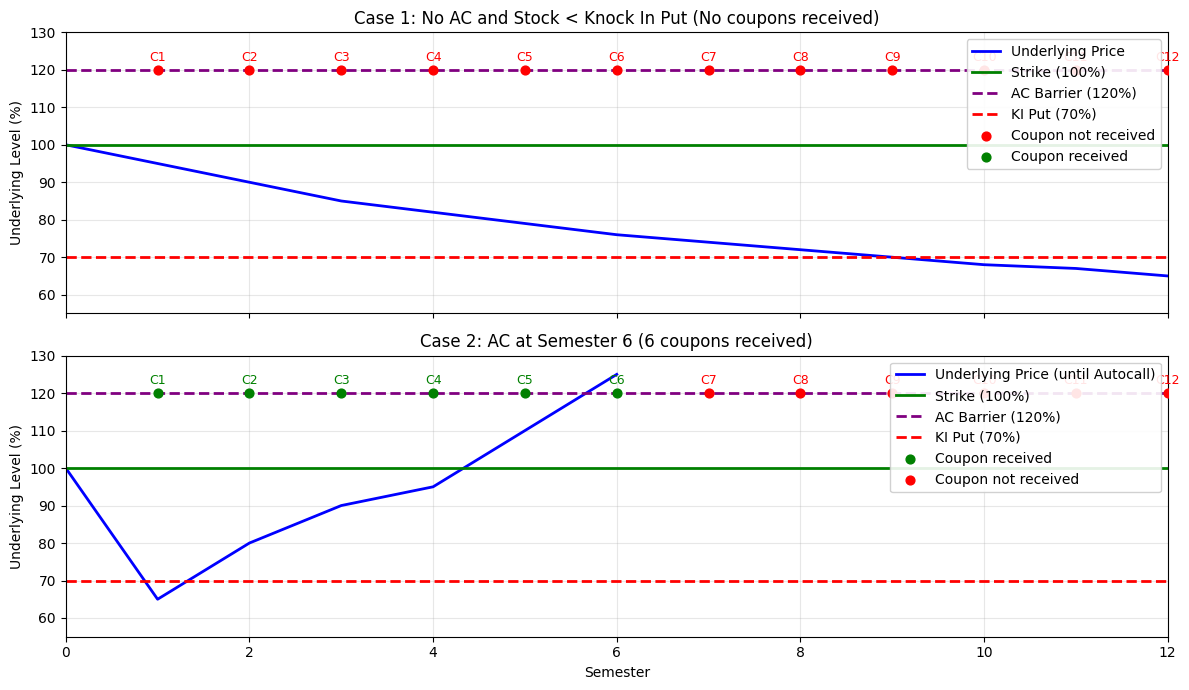

In [33]:
def plot_autocall_coupon_paths():
    # ----------------------------
    # PARAMETERS (in % of S0)
    # ----------------------------
    STRIKE = 100.0
    AC_BARRIER = 120.0
    KI_BARRIER = 70.0

    n_semesters = 12
    semesters = np.arange(0, n_semesters + 1)  # 0..12

    # Coupon observation points are at semesters 1..12
    obs_sem = np.arange(1, n_semesters + 1)
    obs_labels = [f"C{i}" for i in obs_sem]

    # ----------------------------
    # CASE 1: No Autocall, final < KI (no coupons received)
    # Example path: drifts down, ends below 70%
    # ----------------------------
    path_case1 = np.array([100, 95, 90, 85, 82, 79, 76, 74, 72, 70, 68, 67, 65], dtype=float)

    # ----------------------------
    # CASE 2: Autocall at Semester 6 (6 coupons received)
    # Example path: dips then rallies above AC at semester 6
    # Note: after autocall, we do NOT plot the path further (truncate)
    # ----------------------------
    path_case2_full = np.array([100, 65, 80, 90, 95, 110, 125, 120, 118, 121, 119, 122, 120], dtype=float)
    ac_semester = 6  # autocall occurs at semester 6
    path_case2 = path_case2_full[:ac_semester + 1]  # include semester 6 point
    semesters_case2 = semesters[:ac_semester + 1]

    # ----------------------------
    # PLOT SETUP
    # ----------------------------
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    plt.subplots_adjust(hspace=0.35)

    # Helper to draw horizontal levels
    def draw_levels(ax):
        ax.axhline(STRIKE, color='green', linewidth=2, label='Strike (100%)')
        ax.axhline(AC_BARRIER, color='purple', linestyle='--', linewidth=2, label='AC Barrier (120%)')
        ax.axhline(KI_BARRIER, color='red', linestyle='--', linewidth=2, label='KI Put (70%)')
        ax.set_ylim(55, 130)
        ax.set_ylabel('Underlying Level (%)')
        ax.grid(True, alpha=0.3)

    # ----------------------------
    # CASE 1 PLOT
    # ----------------------------
    ax1 = axes[0]
    ax1.set_title('Case 1: No AC and Stock < Knock In Put (No coupons received)')

    ax1.plot(semesters, path_case1, color='blue', linewidth=2, label='Underlying Price')
    draw_levels(ax1)

    # Coupon dots and labels (all NOT received)
    y_coupon_line = AC_BARRIER  # markers displayed on AC barrier line as in your image
    ax1.scatter(obs_sem, np.full_like(obs_sem, y_coupon_line), color='red', s=40, label='Coupon not received', zorder=5)

    for x, lab in zip(obs_sem, obs_labels):
        ax1.text(x, y_coupon_line + 1.5, lab, color='red', ha='center', va='bottom', fontsize=9)

    # Ensure legend order similar to screenshot
    handles, labels = ax1.get_legend_handles_labels()
    # Add a dummy for "Coupon received" so legend shows both
    dummy_received = ax1.scatter([], [], color='green', s=40, label='Coupon received')
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles, labels, loc='upper right', framealpha=0.9)

    # ----------------------------
    # CASE 2 PLOT
    # ----------------------------
    ax2 = axes[1]
    ax2.set_title(f'Case 2: AC at Semester {ac_semester} ({ac_semester} coupons received)')

    ax2.plot(semesters_case2, path_case2, color='blue', linewidth=2, label='Underlying Price (until Autocall)')
    draw_levels(ax2)

    # Coupon received: semesters 1..ac_semester (green)
    received_sem = np.arange(1, ac_semester + 1)
    not_received_sem = np.arange(ac_semester + 1, n_semesters + 1)

    ax2.scatter(received_sem, np.full_like(received_sem, y_coupon_line), color='green', s=40, label='Coupon received', zorder=5)
    ax2.scatter(not_received_sem, np.full_like(not_received_sem, y_coupon_line), color='red', s=40, label='Coupon not received', zorder=5)

    # Labels C1..C12
    for x, lab in zip(obs_sem, obs_labels):
        col = 'green' if x <= ac_semester else 'red'
        ax2.text(x, y_coupon_line + 1.5, lab, color=col, ha='center', va='bottom', fontsize=9)

    ax2.set_xlabel('Semester')
    ax2.set_xlim(0, n_semesters)

    ax2.legend(loc='upper right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

# Run
plot_autocall_coupon_paths()
